# Flow-STP complete Stage 1 workflow on the Qian PFC atlas

This notebook uses only package calls to:

1. Check the active repository and package installation.
2. Load and validate the Qian et al. PFC slices.
3. Optionally merge shared H1/H2/H3 metadata.
4. Run Stage 1a.
5. Run Stage 1b-\(\ell\) and Stage 1b-\(r\).
6. Generate deterministic \(r\) heatmaps over tissue coordinates.
7. Report output paths and remaining Git changes.

The notebook does **not** create a Git commit. Run it first in smoke mode, then switch to full mode after the complete workflow succeeds.

In [10]:
from __future__ import annotations

from pathlib import Path
import importlib
import subprocess
import sys


def run_command(command, *, cwd=None, check=True):
    result = subprocess.run(
        [str(item) for item in command],
        cwd=cwd,
        capture_output=True,
        text=True,
        check=False,
    )

    if check and result.returncode != 0:
        raise RuntimeError(
            f"Command failed: {' '.join(map(str, command))}\n\n"
            f"STDOUT:\n{result.stdout}\n\n"
            f"STDERR:\n{result.stderr}"
        )

    return result


# -------------------------------------------------------------------------
# Locate repository
# -------------------------------------------------------------------------

REPO_ROOT = Path(
    run_command(
        ["git", "rev-parse", "--show-toplevel"]
    ).stdout.strip()
).resolve()

SRC_ROOT = REPO_ROOT / "src"
PACKAGE_ROOT = SRC_ROOT / "flow_stp"
DATA_MODULE = PACKAGE_ROOT / "data" / "qian_pfc.py"

print("Repository:", REPO_ROOT)
print("Notebook Python:", sys.executable)

if not PACKAGE_ROOT.is_dir():
    raise FileNotFoundError(
        f"flow_stp source package was not found: {PACKAGE_ROOT}"
    )

if not DATA_MODULE.is_file():
    raise FileNotFoundError(
        f"Qian PFC loader module was not found: {DATA_MODULE}"
    )


# -------------------------------------------------------------------------
# Check whether Git is ignoring the new data package
# -------------------------------------------------------------------------

ignore_check = run_command(
    [
        "git",
        "check-ignore",
        "-v",
        "src/flow_stp/data/qian_pfc.py",
    ],
    cwd=REPO_ROOT,
    check=False,
)

if ignore_check.returncode == 0:
    print("\nWARNING: Git is ignoring the loader package:")
    print(ignore_check.stdout.strip())
    print(
        "\nA broad .gitignore rule such as 'data/' is probably "
        "matching src/flow_stp/data/. This must be fixed before "
        "the loader commit."
    )
else:
    print("\nGit ignore check: loader package is not ignored.")


# -------------------------------------------------------------------------
# Install the repository into this exact notebook environment
# -------------------------------------------------------------------------

print("\nInstalling flow-stp into the active notebook environment...")

install_result = run_command(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-e",
        str(REPO_ROOT),
    ],
    cwd=REPO_ROOT,
    check=False,
)

print(install_result.stdout)

if install_result.returncode != 0:
    print(install_result.stderr)

    raise RuntimeError(
        "Editable installation failed in the active notebook "
        "environment."
    )


# Add src immediately as an additional safeguard for the current kernel.
src_string = str(SRC_ROOT)

if src_string not in sys.path:
    sys.path.insert(0, src_string)


# -------------------------------------------------------------------------
# Clear stale imports and verify package API
# -------------------------------------------------------------------------

importlib.invalidate_caches()

for module_name in list(sys.modules):
    if (
        module_name == "flow_stp"
        or module_name.startswith("flow_stp.")
    ):
        del sys.modules[module_name]


import flow_stp

from flow_stp import (
    QianPFCConfig,
    load_qian_pfc_for_stage1,
    validate_qian_pfc_data,
)

from flow_stp.stage1 import (
    Stage1ARunConfig,
    Stage1BEllConfig,
    Stage1BRConfig,
    Stage1BPlotConfig,
    plot_stage1b_r,
    run_stage1a,
    run_stage1b,
)


loaded_from = Path(flow_stp.__file__).resolve()

if PACKAGE_ROOT.resolve() not in loaded_from.parents:
    raise RuntimeError(
        "flow_stp imported from the wrong location:\n"
        f"  {loaded_from}\n\n"
        f"Expected it under:\n"
        f"  {PACKAGE_ROOT.resolve()}"
    )


print("\nPackage import succeeded.")
print("flow_stp loaded from:")
print(loaded_from)

print("\nRequired workflow imports:")
for obj in (
    QianPFCConfig,
    load_qian_pfc_for_stage1,
    validate_qian_pfc_data,
    Stage1ARunConfig,
    run_stage1a,
    Stage1BEllConfig,
    Stage1BRConfig,
    run_stage1b,
    Stage1BPlotConfig,
    plot_stage1b_r,
):
    print("  OK:", getattr(obj, "__name__", type(obj).__name__))


# -------------------------------------------------------------------------
# Show focused Git status
# -------------------------------------------------------------------------

print("\nPackage-related Git status:")

status = run_command(
    [
        "git",
        "status",
        "--short",
        "--",
        ".gitignore",
        "pyproject.toml",
        "src/flow_stp/__init__.py",
        "src/flow_stp/data",
        "src/flow_stp/stage1",
        "tests/test_qian_pfc_loader.py",
    ],
    cwd=REPO_ROOT,
).stdout.strip()

print(status or "(no package changes)")

Repository: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow
Notebook Python: /weka/scratch/uchitra1/users/joquinn4/envs/tsc/bin/python3.11

.gitignore:23:data/	src/flow_stp/data/qian_pfc.py

A broad .gitignore rule such as 'data/' is probably matching src/flow_stp/data/. This must be fixed before the loader commit.

Installing flow-stp into the active notebook environment...
Obtaining file:///weka/scratch/uchitra1/users/joquinn4/projects/STP%20flow
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for flow-stp (pyproject

## 1. Git and package preflight

It is safe to test the workflow before committing the loader. This cell reports whether the loader files are still modified or untracked. Do not use `git add .` because the repository contains large untracked notebook outputs.

In [11]:
PACKAGE_PATHS = [
    "src/flow_stp/__init__.py",
    "src/flow_stp/data",
    "src/flow_stp/stage1",
    "tests/test_qian_pfc_loader.py",
    "pyproject.toml",
    ".gitignore",
]

package_status = run_command(
    ["git", "status", "--short", "--", *PACKAGE_PATHS],
    cwd=REPO_ROOT,
).stdout.strip()

print("Package-related Git status:")
print(package_status or "(no package changes)")

if package_status:
    print(
        "\nNOTE: The loader update has not yet been committed. "
        "That is acceptable for this workflow test."
    )

importlib.invalidate_caches()

import flow_stp
from flow_stp import (
    QianPFCConfig,
    load_qian_pfc_for_stage1,
    validate_qian_pfc_data,
)
from flow_stp.stage1 import (
    Stage1ARunConfig,
    Stage1BEllConfig,
    Stage1BRConfig,
    Stage1BPlotConfig,
    plot_stage1b_r,
    run_stage1a,
    run_stage1b,
)

print("\nflow_stp imported from:")
print(Path(flow_stp.__file__).resolve())

required_api = [
    QianPFCConfig,
    load_qian_pfc_for_stage1,
    Stage1ARunConfig,
    run_stage1a,
    Stage1BEllConfig,
    Stage1BRConfig,
    run_stage1b,
    Stage1BPlotConfig,
    plot_stage1b_r,
]

for obj in required_api:
    print("OK:", getattr(obj, "__name__", type(obj).__name__))

Package-related Git status:
M src/flow_stp/__init__.py
?? tests/test_qian_pfc_loader.py

NOTE: The loader update has not yet been committed. That is acceptable for this workflow test.

flow_stp imported from:
/weka/scratch/uchitra1/users/joquinn4/projects/STP flow/src/flow_stp/__init__.py
OK: QianPFCConfig
OK: load_qian_pfc_for_stage1
OK: Stage1ARunConfig
OK: run_stage1a
OK: Stage1BEllConfig
OK: Stage1BRConfig
OK: run_stage1b
OK: Stage1BPlotConfig
OK: plot_stage1b_r


## 2. Workflow settings

Start with `RUN_MODE = "smoke"`. After the complete notebook succeeds, change it to `"full"` and rerun from the data-loading section.

`SHARED_METADATA_FILE` must be the exact CSV, TSV, Parquet, or Feather file. Leave it as `None` when H1/H2/H3 are already present in the h5ad files or when testing the base loader first.

In [12]:
RUN_MODE = "smoke"  # "smoke" or "full"

DATA_ROOT = Path(
    "/scratch/uchitra1/datasets/spatial-RNA/merfish/"
    "merfish_cortex_atlas/zenodo_14422018_processed"
)

# Replace with the exact shared metadata file when needed.
SHARED_METADATA_FILE = None
# Example:
# SHARED_METADATA_FILE = Path(
#     "/path/to/lab/shared/qian_pfc_cell_metadata.parquet"
# )

SHARED_METADATA_JOIN_ON = ("gw", "cell_id")

OUTPUT_ROOT = (
    REPO_ROOT
    / "notebooks"
    / "flow_stp_package_full_stage1_workflow"
    / RUN_MODE
).resolve()

STAGE1A_OUTPUT = OUTPUT_ROOT / "stage1a"
STAGE1B_ELL_OUTPUT = OUTPUT_ROOT / "stage1b_ell"
STAGE1B_R_OUTPUT = OUTPUT_ROOT / "stage1b_r"
MANUAL_PLOT_OUTPUT = OUTPUT_ROOT / "manual_r_heatmaps"

for path in (
    OUTPUT_ROOT,
    STAGE1A_OUTPUT,
    STAGE1B_ELL_OUTPUT,
    STAGE1B_R_OUTPUT,
    MANUAL_PLOT_OUTPUT,
):
    path.mkdir(parents=True, exist_ok=True)

if RUN_MODE == "smoke":
    MAX_CELLS_PER_SLICE = 250
    MAX_GENES_FOR_DEBUG = 300
    STAGE1A_EPOCHS = 2
    STAGE1A_BATCH_SIZE = 128

    ELL_GRID_MAX_DIM = 96
    ELL_N_REFERENCE_LEVELS = 20
    ELL_BACKFLOW_STEPS = 16

    R_N_ELL_TRAJECTORIES = 48
    R_N_Z_SAMPLES = 41
elif RUN_MODE == "full":
    MAX_CELLS_PER_SLICE = None
    MAX_GENES_FOR_DEBUG = None
    STAGE1A_EPOCHS = 1500
    STAGE1A_BATCH_SIZE = 1024

    ELL_GRID_MAX_DIM = 360
    ELL_N_REFERENCE_LEVELS = 100
    ELL_BACKFLOW_STEPS = 64

    R_N_ELL_TRAJECTORIES = 256
    R_N_Z_SAMPLES = 181
else:
    raise ValueError("RUN_MODE must be 'smoke' or 'full'.")

print("Run mode:", RUN_MODE)
print("Output root:", OUTPUT_ROOT)
print("Shared metadata:", SHARED_METADATA_FILE)

Run mode: smoke
Output root: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke
Shared metadata: None


## 3. Load the Qian PFC atlas

The result object exposes the exact arguments accepted by `run_stage1a` through `qian_pfc.as_stage1_kwargs()`.

In [13]:
qian_config = QianPFCConfig(
    data_root=DATA_ROOT,
    max_cells_per_slice=MAX_CELLS_PER_SLICE,
    max_genes_for_debug=MAX_GENES_FOR_DEBUG,
    expected_num_slices=10,
    shared_metadata_path=SHARED_METADATA_FILE,
    shared_metadata_join_on=(
        SHARED_METADATA_JOIN_ON
        if SHARED_METADATA_FILE is not None
        else None
    ),
)

qian_pfc = load_qian_pfc_for_stage1(qian_config)
validate_qian_pfc_data(qian_pfc)

counts_by_slice = qian_pfc.counts_by_slice
obs_df = qian_pfc.obs_df
panel_df = qian_pfc.panel_df
gene_names = qian_pfc.gene_names
spatial_by_slice = qian_pfc.spatial_by_slice

print("\nLoaded Stage 1 inputs")
print("  slices:", qian_pfc.num_slices)
print("  cells:", f"{qian_pfc.num_cells:,}")
print("  genes:", f"{qian_pfc.num_genes:,}")

display(
    panel_df[
        [
            column
            for column in (
                "slice_id",
                "panel_key",
                "gw",
                "time",
                "sample",
                "region",
                "n_full",
            )
            if column in panel_df.columns
        ]
    ]
)

Reading obs for GW15: /weka/scratch/uchitra1/datasets/spatial-RNA/merfish/merfish_cortex_atlas/zenodo_14422018_processed/gw15.h5ad
Reading obs for GW20: /weka/scratch/uchitra1/datasets/spatial-RNA/merfish/merfish_cortex_atlas/zenodo_14422018_processed/gw20.h5ad
Reading obs for GW22: /weka/scratch/uchitra1/datasets/spatial-RNA/merfish/merfish_cortex_atlas/zenodo_14422018_processed/gw22.h5ad
Reading obs for GW34: /weka/scratch/uchitra1/datasets/spatial-RNA/merfish/merfish_cortex_atlas/zenodo_14422018_processed/gw34.h5ad


/weka/scratch/uchitra1/users/joquinn4/envs/tsc/lib/python3.11/site-packages/anndata/_core/anndata.py:1878: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")



Loading Qian PFC panels for Flow-STP

Loading slice 00: GW15 | UMB1117 | F1a
 h5ad: /weka/scratch/uchitra1/datasets/spatial-RNA/merfish/merfish_cortex_atlas/zenodo_14422018_processed/gw15.h5ad
 downsampled to 250 cells
 cells: 250
 expression shape: (250, 300)
 spatial shape: (250, 2)
 count mean: 0.1330
 count max: 3.2042

Loading slice 01: GW15 | UMB1117 | F1b
 h5ad: /weka/scratch/uchitra1/datasets/spatial-RNA/merfish/merfish_cortex_atlas/zenodo_14422018_processed/gw15.h5ad
 downsampled to 250 cells
 cells: 250
 expression shape: (250, 300)
 spatial shape: (250, 2)
 count mean: 0.0985
 count max: 3.0617

Loading slice 02: GW20 | FB080 | F1
 h5ad: /weka/scratch/uchitra1/datasets/spatial-RNA/merfish/merfish_cortex_atlas/zenodo_14422018_processed/gw20.h5ad
 downsampled to 250 cells
 cells: 250
 expression shape: (250, 300)
 spatial shape: (250, 2)
 count mean: 0.0829
 count max: 2.8405

Loading slice 03: GW20 | FB080 | F2a
 h5ad: /weka/scratch/uchitra1/datasets/spatial-RNA/merfish/merf

/weka/scratch/uchitra1/users/joquinn4/envs/tsc/lib/python3.11/site-packages/anndata/_core/anndata.py:1878: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


 downsampled to 250 cells
 cells: 250
 expression shape: (250, 300)
 spatial shape: (250, 2)
 count mean: 0.1081
 count max: 3.0274

Finished loading Qian PFC Flow-STP input data
 total cells: 2,500
 total slices: 10
 genes: 300

Loaded Stage 1 inputs
  slices: 10
  cells: 2,500
  genes: 300


,slice_id,panel_key,gw,time,sample,region,n_full
0,0,GW15 | UMB1117 | F1a,GW15,15.0,UMB1117,F1a,548567
1,1,GW15 | UMB1117 | F1b,GW15,15.0,UMB1117,F1b,410492
2,2,GW20 | FB080 | F1,GW20,20.0,FB080,F1,665204
3,3,GW20 | FB080 | F2a,GW20,20.0,FB080,F2a,596754
4,4,GW20 | FB080 | F2b,GW20,20.0,FB080,F2b,322648
5,5,GW20 | FB121 | F1,GW20,20.0,FB121,F1,553738
6,6,GW22 | FB123 | F1,GW22,22.0,FB123,F1,508417
7,7,GW22 | FB123 | F2,GW22,22.0,FB123,F2,439986
8,8,GW22 | FB123 | F3,GW22,22.0,FB123,F3,333113
9,9,GW34 | UMB5900 | BA9,GW34,34.0,UMB5900,BA9,146612


## 4. Inspect H1/H2/H3 metadata coverage

In [14]:
metadata_rows = []

for column in ("H1", "H2", "H3"):
    if column not in obs_df.columns:
        metadata_rows.append(
            {
                "level": column,
                "present": False,
                "non_unknown": 0,
                "fraction_non_unknown": 0.0,
                "n_unique": 0,
            }
        )
        continue

    values = obs_df[column].fillna("Unknown").astype(str)
    known = ~values.str.lower().isin(
        {"unknown", "nan", "none", ""}
    )

    metadata_rows.append(
        {
            "level": column,
            "present": True,
            "non_unknown": int(known.sum()),
            "fraction_non_unknown": float(known.mean()),
            "n_unique": int(values[known].nunique()),
        }
    )

metadata_coverage = pd.DataFrame(metadata_rows)
display(metadata_coverage)

if not metadata_coverage["present"].all():
    warnings.warn(
        "At least one H1/H2/H3 column is absent. Check the exact "
        "shared metadata file and join key before the full run."
    )

,level,present,non_unknown,fraction_non_unknown,n_unique
0,H1,True,2500,1.0000,10
1,H2,True,2500,1.0000,81
2,H3,True,703,0.2812,102


## 5. Run Stage 1a

This preserves the current joint coordinate, velocity, and expression-decoder implementation. Checkpoint resumption is enabled, so rerunning the cell should reuse a compatible existing run.

Submersion fixed Stage 1a run output: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1a
Device: cpu
Selected submersion weight: 0.11364637
Prepared 10 slices, 300 genes, 2,500 observations.
Raw times: [15. 15. 20. 20. 20. 20. 22. 22. 22. 34.]
Normalized times: [0.         0.         0.2631579  0.2631579  0.2631579  0.2631579
 0.36842105 0.36842105 0.36842105 1.        ]

Stage 1a fixed run | lambda_sub = 0.11364637
epoch 00001 | total=1.19958 | data=1.12679 | sub=0.64048 | lambda*sub=0.07279 | g_p05=0.00263 | viol=100.0% | elapsed=0.2 min
epoch 00002 | total=1.10602 | data=1.05813 | sub=0.42147 | lambda*sub=0.04790 | g_p05=0.00846 | viol=100.0% | elapsed=0.4 min
Completed lambda=0.11364637 | validation NLL=1.000107 | fixed g_p05=0.014715 | fixed violation=98.80%

Fixed Stage 1a training finished in 0.55 minutes.


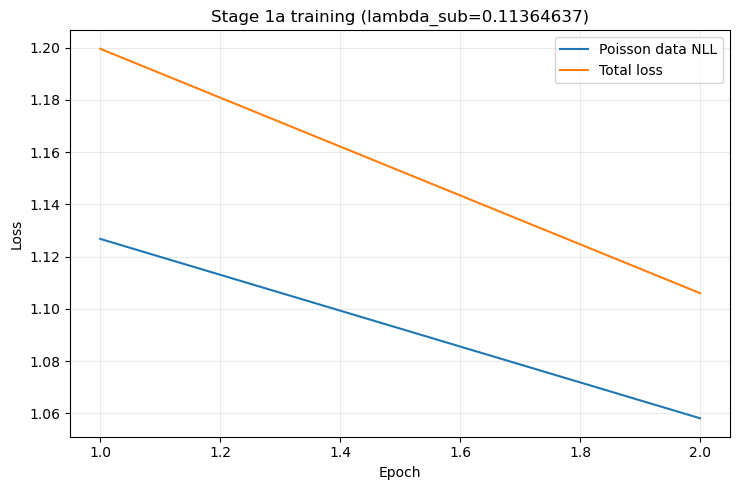

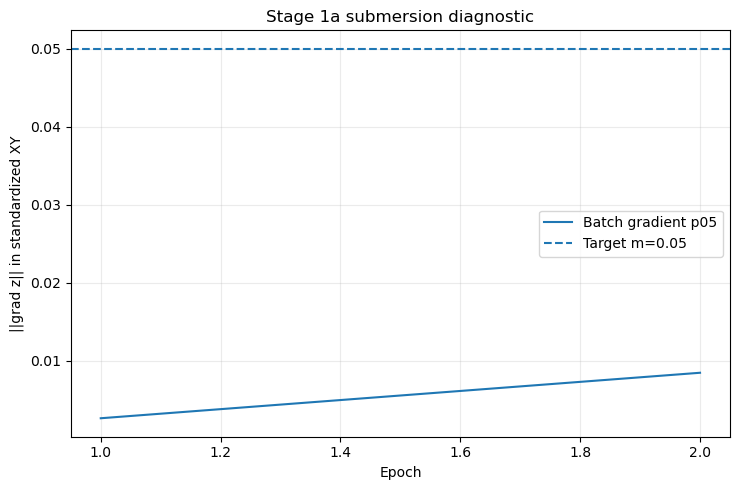


Stage 1a model is ready for Stage 1b.
Model: FlowSTPModel
Device: cpu
Submersion weight: 0.11364637
Output root: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1a
Validation Poisson NLL: 1.0001072037760417
Fixed gradient p05: 0.014715216821059585
Fixed violation fraction: 0.988

Stage 1a completed
Output: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1a
Cell-coordinate rows: 2500


,run_index,submersion_weight,epoch,loss,data_nll,submersion_penalty,weighted_submersion_penalty,batch_grad_min,batch_grad_p05,batch_grad_median,batch_grad_mean,batch_grad_violation_fraction,z_mean,a_mean,rho_mean,parameter_grad_norm_before_clip,elapsed_sec
0,0,0.113646,1,1.199577,1.126788,0.640484,0.072789,0.000553,0.002630,0.009038,0.010411,1.0,0.502301,0.491469,0.149661,0.334963,13.576795
1,0,0.113646,2,1.106024,1.058125,0.421471,0.047899,0.003279,0.008463,0.016503,0.018345,1.0,0.501952,0.469343,0.517972,0.308125,26.815954


,run_index,submersion_weight,slice_id,n_diagnostic,interval_a,interval_b,interval_width,z_min,z_p01,z_p05,...,grad_std_mean,grad_std_p95,grad_std_max,grad_native_min,grad_native_p01,grad_native_p05,grad_native_median,grad_native_mean,grad_native_p95,grad_native_max
0,0,0.113646,0,250,0.237147,0.762622,0.525475,0.437737,0.440260,0.448827,...,0.038938,0.050747,0.051410,0.000004,0.000005,0.000009,0.000021,0.000020,0.000026,0.000027
1,0,0.113646,1,250,0.237154,0.762627,0.525473,0.464790,0.469270,0.477030,...,0.028022,0.034636,0.035776,0.000012,0.000013,0.000014,0.000020,0.000020,0.000025,0.000025
2,0,0.113646,2,250,0.237158,0.762632,0.525474,0.439271,0.441051,0.446055,...,0.026689,0.038585,0.040066,0.000003,0.000003,0.000004,0.000008,0.000008,0.000010,0.000010
3,0,0.113646,3,250,0.237157,0.762633,0.525475,0.426599,0.430413,0.436426,...,0.032641,0.043664,0.044553,0.000003,0.000005,0.000007,0.000013,0.000012,0.000016,0.000016
4,0,0.113646,4,250,0.237156,0.762622,0.525467,0.466892,0.467350,0.471471,...,0.020395,0.024540,0.025328,0.000006,0.000006,0.000007,0.000009,0.000009,0.000011,0.000012
5,0,0.113646,5,250,0.237149,0.762622,0.525473,0.470234,0.471723,0.475424,...,0.027321,0.034644,0.035722,0.000007,0.000007,0.000008,0.000010,0.000010,0.000013,0.000014
6,0,0.113646,6,250,0.237154,0.762617,0.525463,0.476465,0.477868,0.480400,...,0.021147,0.026457,0.027951,0.000005,0.000005,0.000005,0.000008,0.000007,0.000009,0.000010
7,0,0.113646,7,250,0.237157,0.762627,0.525471,0.447823,0.449779,0.459931,...,0.022217,0.028069,0.029107,0.000006,0.000006,0.000007,0.000013,0.000012,0.000015,0.000016
8,0,0.113646,8,250,0.237151,0.762624,0.525473,0.443914,0.444333,0.450347,...,0.019471,0.028100,0.029316,0.000002,0.000002,0.000004,0.000007,0.000008,0.000010,0.000011
9,0,0.113646,9,250,0.237149,0.762624,0.525475,0.449484,0.452468,0.455506,...,0.029367,0.038597,0.039509,0.000006,0.000007,0.000008,0.000015,0.000014,0.000018,0.000019


In [15]:
stage1a_config = Stage1ARunConfig(
    output_dir=STAGE1A_OUTPUT,
    submersion_weight=0.11364637,
    epochs=STAGE1A_EPOCHS,
    batch_size_per_slice=STAGE1A_BATCH_SIZE,
    learning_rate=1e-3,
    resume=True,
)

stage1a = run_stage1a(
    **qian_pfc.as_stage1_kwargs(),
    config=stage1a_config,
)

model_flow_stp = stage1a.model
xy_norm_params = stage1a.xy_norm_params
panel_df_flow_stp = stage1a.panel_df
stage1a_cells = stage1a.cells

print("\nStage 1a completed")
print("Output:", stage1a.output_dir)
print("Cell-coordinate rows:", len(stage1a.cells))
display(stage1a.history.tail())
display(stage1a.coordinate_diagnostics)

## 6. Run Stage 1b-\(\ell\) and deterministic Stage 1b-\(r\)

Stage 1b uses the frozen Stage 1a coordinate field and the original raw tissue coordinates.

In [19]:
ell_config = Stage1BEllConfig(
    output_dir=STAGE1B_ELL_OUTPUT,
    grid_max_dim=ELL_GRID_MAX_DIM,
    n_reference_levels=ELL_N_REFERENCE_LEVELS,
    master_level_quantile=0.50,
    backflow_n_steps=ELL_BACKFLOW_STEPS,
    circular_average_top_k=8,
    circular_average_temperature=2.0,
)

r_config = Stage1BRConfig(
    output_dir=STAGE1B_R_OUTPUT,
    n_ell_trajectories=R_N_ELL_TRAJECTORIES,
    n_z_samples=R_N_Z_SAMPLES,
    flow_substeps_per_z_interval=2,
    assign_k_nearest=8,
)

stage1b = run_stage1b(
    model=model_flow_stp,
    spatial_by_slice=spatial_by_slice,
    xy_norm_params=xy_norm_params,
    panel_df=panel_df_flow_stp,
    ell_config=ell_config,
    r_config=r_config,
)

print("\nStage 1b completed")
print("ell cell rows:", len(stage1b.ell.cells))
print("r cell rows:", len(stage1b.r.cells))

print("\nell summary")
display(stage1b.ell.summary)

print("\nr summary")
display(stage1b.r.summary)

ell_failures = stage1b.ell.failures
r_failures = stage1b.r.failures

if ell_failures is not None and not ell_failures.empty:
    print("ell failures:")
    display(ell_failures)
else:
    print("ell failures: none")

if r_failures is not None and not r_failures.empty:
    print("r failures:")
    display(r_failures)
else:
    print("r failures: none")

Stage 1b ell: slice 0
  slice 00 cells 0-250: circular ell valid 100.0%, mean candidates 4.70
Stage 1b ell: slice 1
  slice 01 cells 0-250: circular ell valid 100.0%, mean candidates 4.96
Stage 1b ell: slice 2
  slice 02 cells 0-250: circular ell valid 100.0%, mean candidates 3.45
Stage 1b ell: slice 3
  slice 03 cells 0-250: circular ell valid 100.0%, mean candidates 4.34
Stage 1b ell: slice 4
  slice 04 cells 0-250: circular ell valid 100.0%, mean candidates 4.00
Stage 1b ell: slice 5
  slice 05 cells 0-250: circular ell valid 100.0%, mean candidates 3.97
Stage 1b ell: slice 6
  slice 06 cells 0-250: circular ell valid 100.0%, mean candidates 3.45
Stage 1b ell: slice 7
  slice 07 cells 0-250: circular ell valid 100.0%, mean candidates 4.46
Stage 1b ell: slice 8
  slice 08 cells 0-250: circular ell valid 100.0%, mean candidates 3.61
Stage 1b ell: slice 9
  slice 09 cells 0-250: circular ell valid 100.0%, mean candidates 4.46
Stage 1b r: slice 0
Stage 1b r: slice 1
Stage 1b r: slice 2


,slice_id,panel_label,n_cells,n_requested_levels,n_unique_levels,n_levels_with_contours,n_selected_level_components_used,master_level_index,master_z_level,master_component_index,...,z_backflow_abs_error_median,z_backflow_abs_error_q90,cell_contour_alignment_valid_fraction_median,contour_alignment_valid_fraction_median,contour_alignment_valid_fraction_q10,ell_circular_resultant_median,ell_circular_resultant_q10,ell_candidate_count_mean,ell_best_circular_abs_delta_median,ell_best_circular_abs_delta_q90
0,0,GW15 | UMB1117 | F1a,250,20,21,21,21,10,0.514282,0,...,0.000221,0.001022,0.994141,0.994141,0.000000,1.000000,0.936958,4.696,0.000007,0.023559
1,1,GW15 | UMB1117 | F1b,250,20,21,21,21,10,0.510393,0,...,0.000184,0.000538,0.872559,0.872559,0.291992,1.000000,0.954962,4.964,0.000014,0.032317
2,2,GW20 | FB080 | F1,250,20,21,21,21,10,0.485243,0,...,0.000563,0.001619,0.000000,0.000000,0.000000,0.998993,0.955644,3.448,0.002395,0.025776
3,3,GW20 | FB080 | F2a,250,20,21,21,21,10,0.479254,0,...,0.000481,0.001466,0.694336,0.694336,0.000000,0.997661,0.911734,4.336,0.003238,0.039736
4,4,GW20 | FB080 | F2b,250,20,21,21,21,10,0.512807,0,...,0.000361,0.001217,0.000000,0.000000,0.000000,0.999326,0.972774,3.996,0.002831,0.019060
5,5,GW20 | FB121 | F1,250,20,21,21,21,10,0.516618,0,...,0.000426,0.001157,0.137695,0.137695,0.000000,0.998887,0.880400,3.968,0.001744,0.046614
6,6,GW22 | FB123 | F1,250,20,21,21,21,10,0.510482,0,...,0.000461,0.001236,0.000000,0.000000,0.000000,0.993681,0.982643,3.452,0.006594,0.017693
7,7,GW22 | FB123 | F2,250,20,21,21,21,10,0.488300,0,...,0.000347,0.000975,0.576172,0.576172,0.000000,0.999740,0.941844,4.460,0.001264,0.027436
8,8,GW22 | FB123 | F3,250,20,21,21,21,10,0.482679,0,...,0.000384,0.001192,0.000000,0.000000,0.000000,0.998043,0.972687,3.612,0.002970,0.017446
9,9,GW34 | UMB5900 | BA9,250,20,21,21,21,10,0.496271,0,...,0.000406,0.001177,0.787109,0.787109,0.000000,0.999973,0.935649,4.460,0.000258,0.040195



r summary


,slice_id,panel_label,n_cells,r_valid_fraction,ell_valid_fraction,n_ell_trajectories,n_z_samples,n_valid_trajectories,valid_trajectory_fraction,z_min_chart,...,r_normalized_std,r_normalized_q01,r_normalized_q99,trajectory_total_length_median,trajectory_total_length_q10,trajectory_total_length_q90,assignment_feature_distance_median,assignment_feature_distance_q90,r_z_extrapolated_or_clipped_fraction,r_z_spearman
0,0,GW15 | UMB1117 | F1a,250,1.0,1.0,48,42,48,1.000000,0.438147,...,0.264414,0.028940,0.993936,5020.833880,3756.401367,5231.316221,0.037511,0.061148,0.016,0.997605
1,1,GW15 | UMB1117 | F1b,250,1.0,1.0,48,42,48,1.000000,0.466896,...,0.278043,0.031090,0.974862,3911.292690,3616.256984,4534.072164,0.037143,0.060874,0.016,0.999769
2,2,GW20 | FB080 | F1,250,1.0,1.0,48,42,47,0.979167,0.440793,...,0.264468,0.016026,0.980530,4024.331993,2833.381422,4642.310626,0.038474,0.062905,0.016,0.992883
3,3,GW20 | FB080 | F2a,250,1.0,1.0,48,42,48,1.000000,0.428251,...,0.265214,0.027706,0.979415,6070.282771,4159.284683,6323.996269,0.037735,0.059787,0.016,0.999743
4,4,GW20 | FB080 | F2b,250,1.0,1.0,48,42,48,1.000000,0.467064,...,0.286730,0.022089,0.970213,3832.920286,3420.095777,3897.283709,0.036035,0.061834,0.016,0.999191
5,5,GW20 | FB121 | F1,250,1.0,1.0,48,42,48,1.000000,0.471067,...,0.275219,0.016749,0.991247,4693.827408,3431.366668,4771.356685,0.034942,0.063242,0.016,0.999879
6,6,GW22 | FB123 | F1,250,1.0,1.0,48,42,48,1.000000,0.477698,...,0.271469,0.018765,0.971936,3675.571633,3149.836348,3788.341561,0.038748,0.061596,0.016,0.999667
7,7,GW22 | FB123 | F2,250,1.0,1.0,48,42,48,1.000000,0.448597,...,0.253017,0.024183,0.978282,4458.391399,4281.880513,4575.435217,0.038007,0.062203,0.016,0.999891
8,8,GW22 | FB123 | F3,250,1.0,1.0,48,42,48,1.000000,0.444133,...,0.309185,0.020134,0.985463,3521.990558,3406.774872,3554.736616,0.037823,0.062126,0.016,0.999821
9,9,GW34 | UMB5900 | BA9,250,1.0,1.0,48,42,48,1.000000,0.452316,...,0.270210,0.011239,0.974939,5236.952473,3602.993639,5584.849266,0.037611,0.062664,0.016,0.998556


ell failures: none
r failures: none


## 7. Generate package \(r\) heatmaps

This plotting call uses the saved Stage 1b results and does not rerun the geometry.

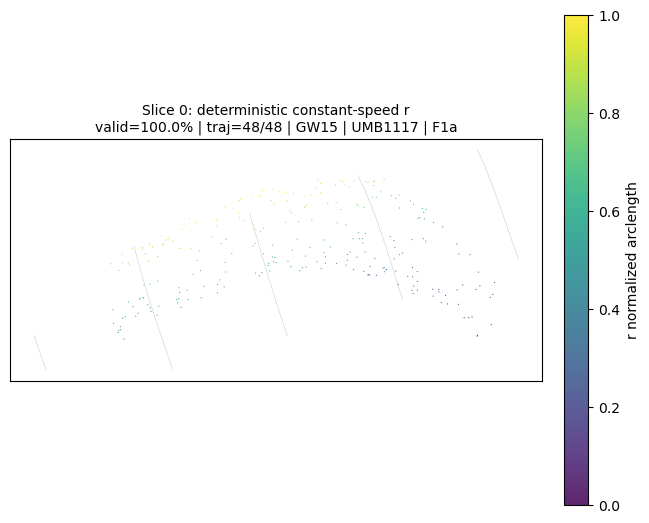

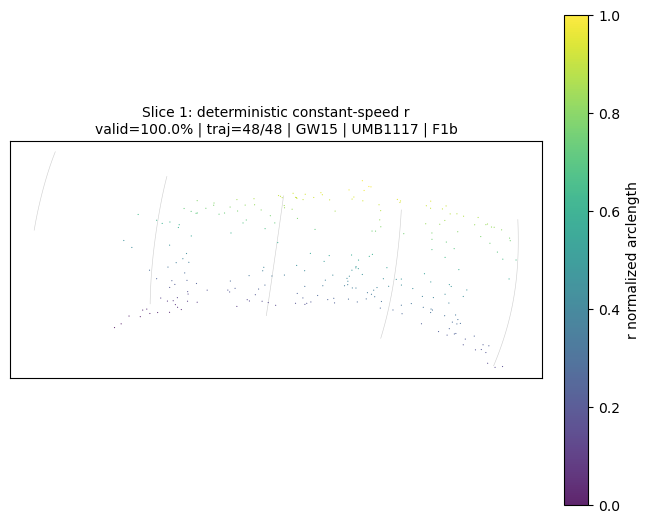

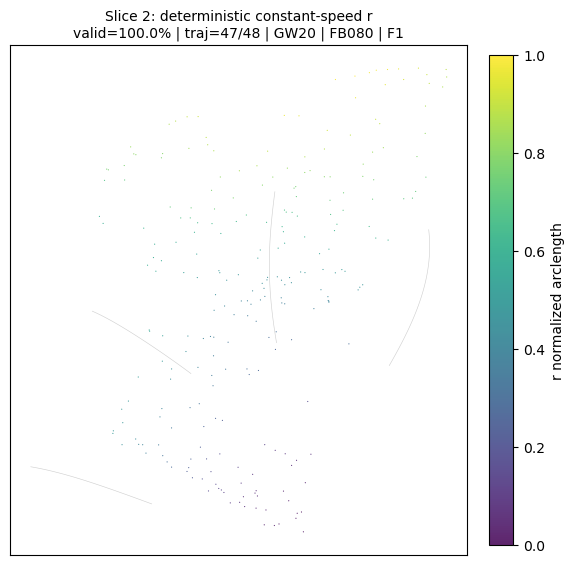

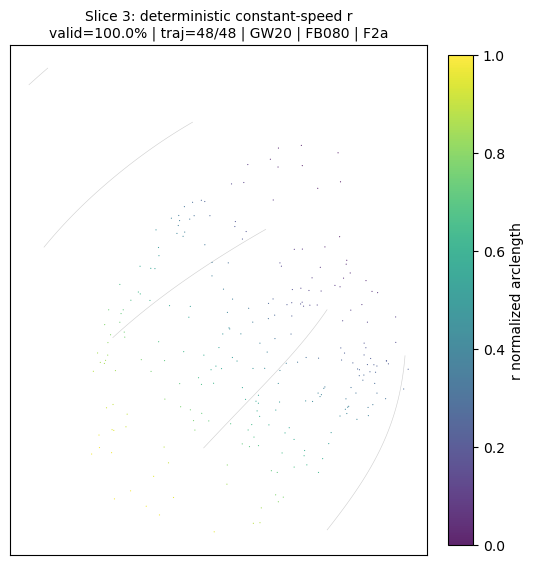

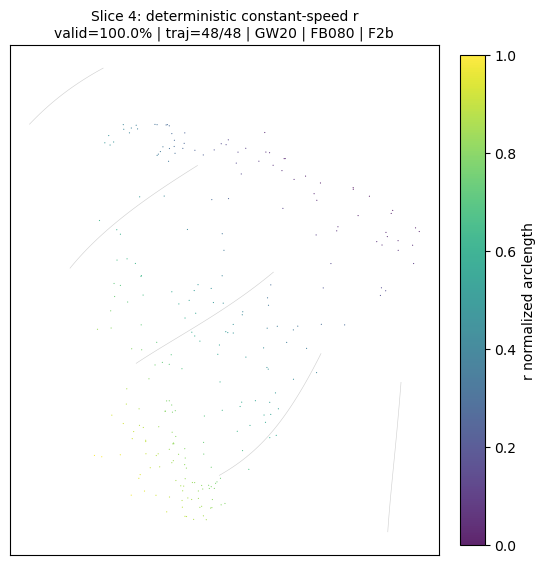

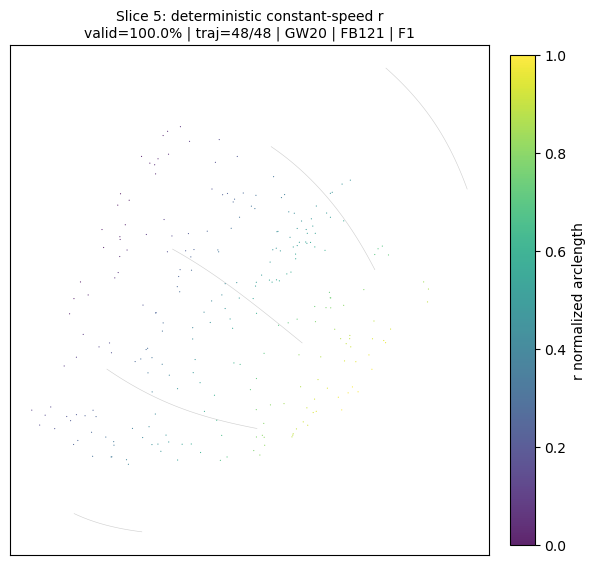

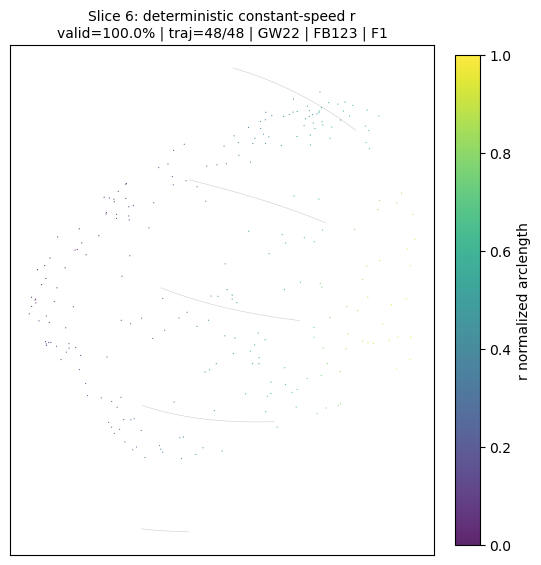

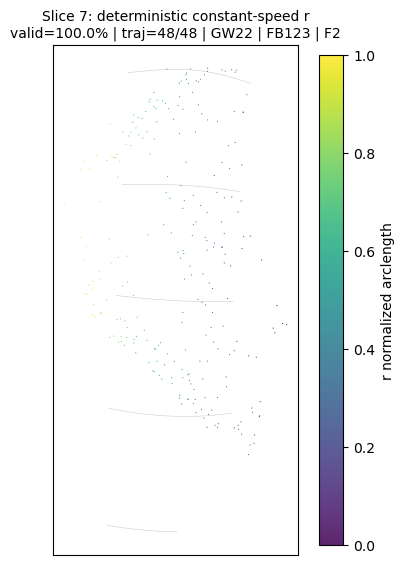

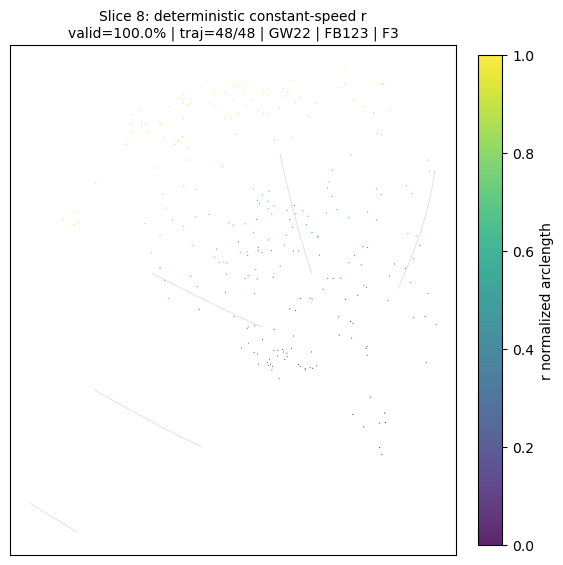

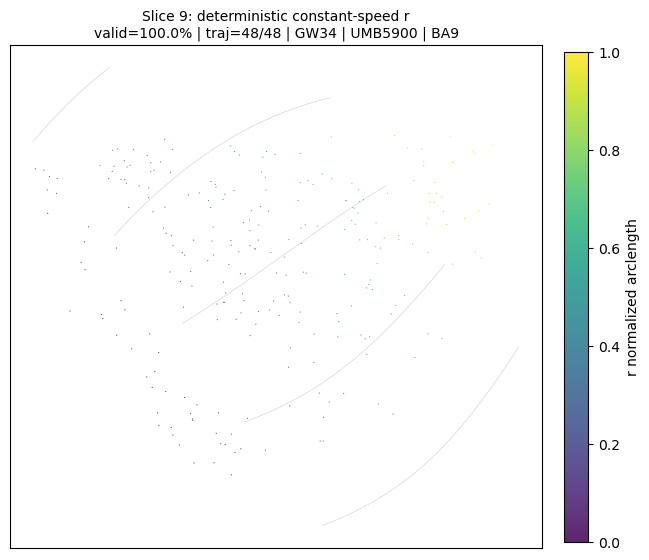

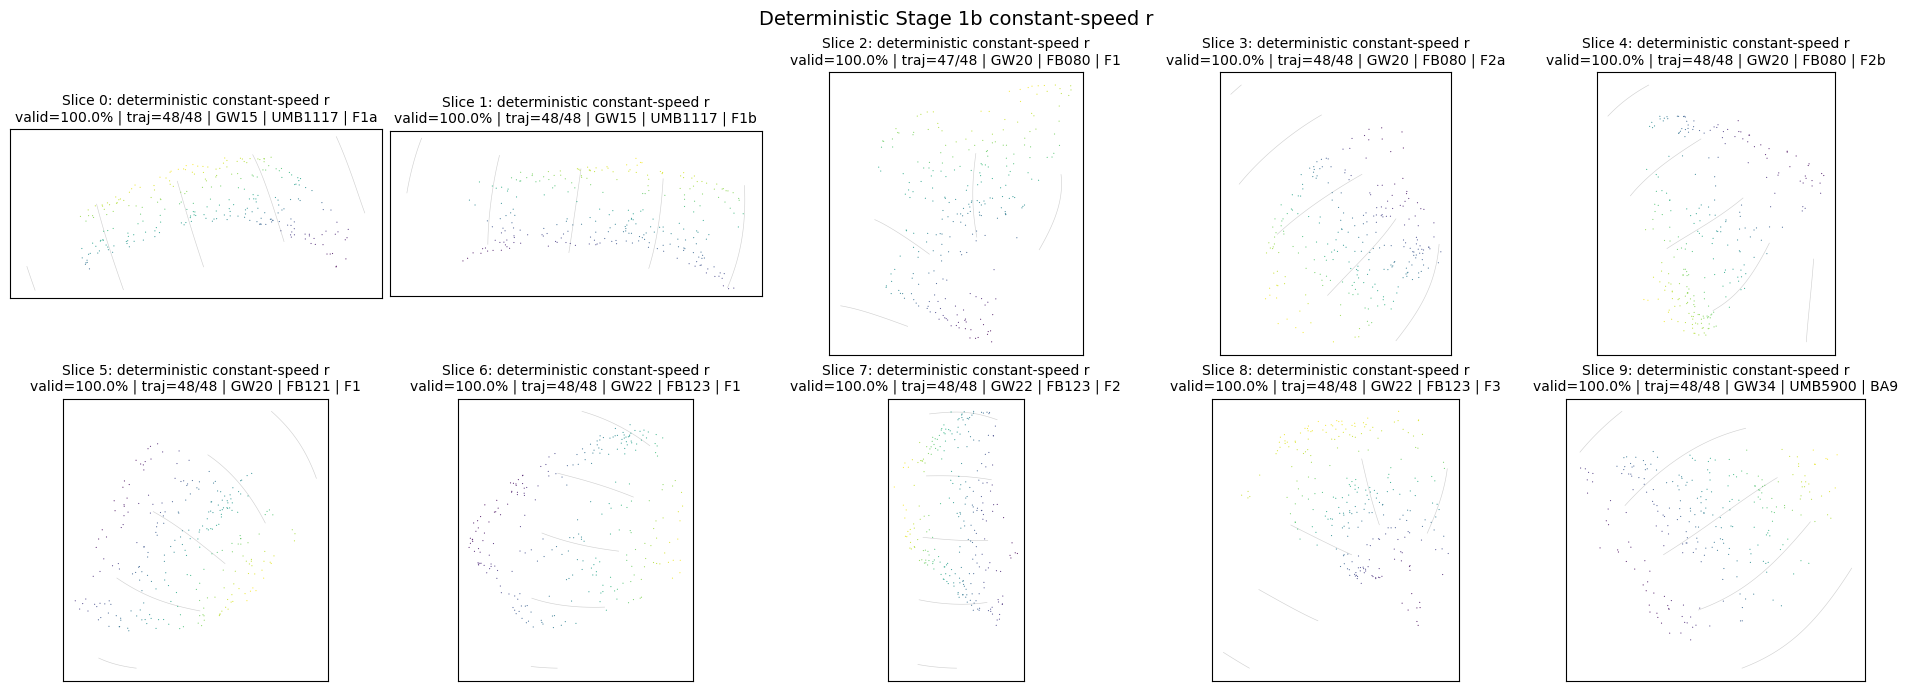

Package-generated r heatmaps:
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_00_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_01_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_02_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_03_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_04_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_05_determin

In [20]:
plot_config = Stage1BPlotConfig(
    display=True,
    save_png=True,
    save_pdf=False,
    dpi=300,
    max_points_per_plot=140_000,
    point_size=0.7,
    point_alpha=0.86,
    r_cmap="viridis",
    make_overview=True,
    overview_ncols=5,
)

r_plot_artifacts = plot_stage1b_r(
    stage1b.r,
    config=plot_config,
)

print("Package-generated r heatmaps:")
for path in r_plot_artifacts.files:
    print(" ", path)

## 8. Independent overview: \(r\) over raw tissue coordinates

This cell provides a lightweight visual cross-check using the combined Stage 1b cell table. It automatically detects the coordinate, \(r\), and validity columns.

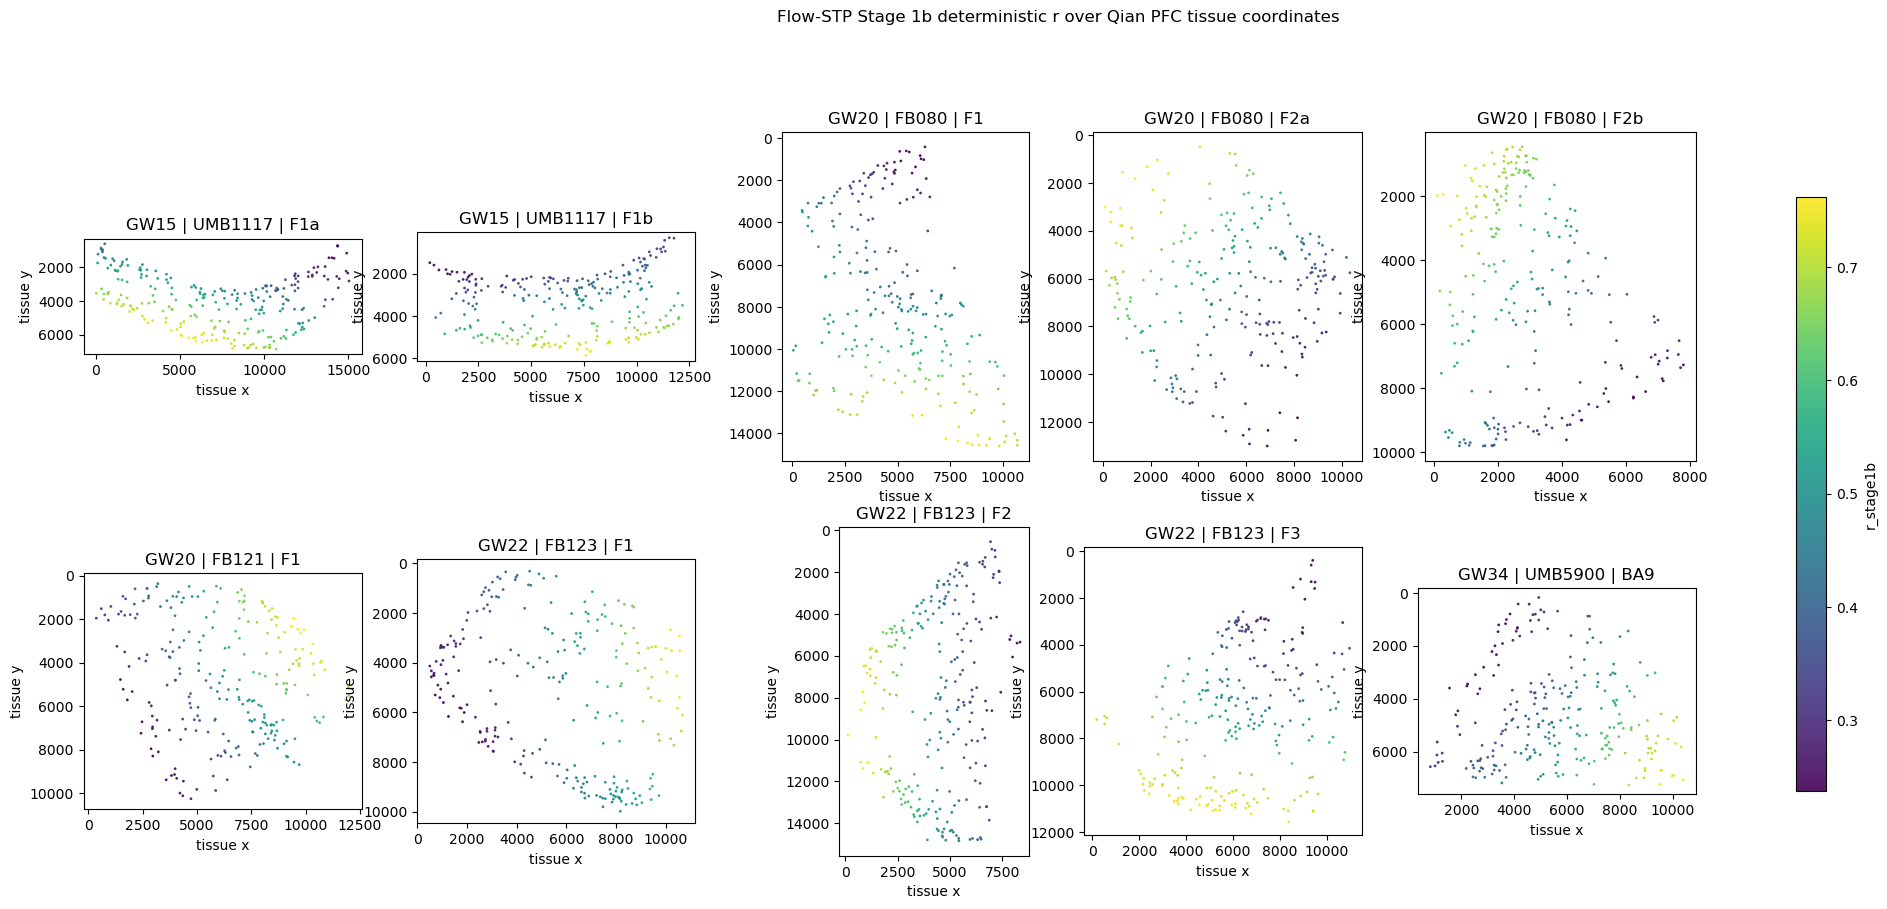

Saved: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/manual_r_heatmaps/all_slices_stage1b_r_tissue_heatmaps.png


In [21]:
r_cells = stage1b.r.cells.copy()

def first_existing(frame, candidates, *, required=True):
    for candidate in candidates:
        if candidate in frame.columns:
            return candidate
    if required:
        raise KeyError(
            "None of these columns were found: "
            + ", ".join(candidates)
        )
    return None


x_column = first_existing(
    r_cells,
    ("x", "spatial_x", "raw_x"),
)
y_column = first_existing(
    r_cells,
    ("y", "spatial_y", "raw_y"),
)
r_column = first_existing(
    r_cells,
    (
        "r_stage1b",
        "r_normalized",
        "r_deterministic",
        "r",
    ),
)
valid_column = first_existing(
    r_cells,
    (
        "r_valid",
        "assign_valid",
        "assignment_valid",
        "valid",
    ),
    required=False,
)

slice_ids = sorted(
    int(value)
    for value in pd.unique(r_cells["slice_id"])
)

ncols = min(5, max(1, len(slice_ids)))
nrows = int(math.ceil(len(slice_ids) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5.2 * ncols, 4.7 * nrows),
    squeeze=False,
)

scatter_for_colorbar = None

for axis, slice_id in zip(axes.ravel(), slice_ids):
    table = r_cells[
        r_cells["slice_id"].astype(int) == slice_id
    ].copy()

    valid = (
        np.isfinite(table[x_column].to_numpy(dtype=float))
        & np.isfinite(table[y_column].to_numpy(dtype=float))
        & np.isfinite(table[r_column].to_numpy(dtype=float))
    )

    if valid_column is not None:
        valid &= table[valid_column].astype(bool).to_numpy()

    table = table.loc[valid]

    scatter_for_colorbar = axis.scatter(
        table[x_column],
        table[y_column],
        c=table[r_column],
        s=1.0,
        alpha=0.9,
        cmap="viridis",
        rasterized=True,
    )

    panel_hit = panel_df_flow_stp[
        panel_df_flow_stp["slice_id"].astype(int) == slice_id
    ]

    if len(panel_hit) and "panel_key" in panel_hit.columns:
        title = str(panel_hit.iloc[0]["panel_key"])
    else:
        title = f"slice {slice_id}"

    axis.set_title(title)
    axis.set_aspect("equal")
    axis.invert_yaxis()
    axis.set_xlabel("tissue x")
    axis.set_ylabel("tissue y")

for axis in axes.ravel()[len(slice_ids):]:
    axis.axis("off")

if scatter_for_colorbar is not None:
    colorbar = fig.colorbar(
        scatter_for_colorbar,
        ax=list(axes.ravel()[: len(slice_ids)]),
        shrink=0.82,
    )
    colorbar.set_label(r_column)

fig.suptitle(
    "Flow-STP Stage 1b deterministic r over Qian PFC tissue coordinates",
    y=1.01,
)

overview_path = (
    MANUAL_PLOT_OUTPUT
    / "all_slices_stage1b_r_tissue_heatmaps.png"
)

fig.savefig(
    overview_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Saved:", overview_path)

## 9. Validate final pipeline outputs

In [22]:
assert qian_pfc.num_slices == len(spatial_by_slice)
assert len(stage1a.cells) == qian_pfc.num_cells
assert len(stage1b.ell.cells) == qian_pfc.num_cells
assert len(stage1b.r.cells) == qian_pfc.num_cells

if "slice_id" not in stage1b.r.cells.columns:
    raise KeyError("Stage 1b r cell table lacks slice_id.")

if not np.isfinite(
    stage1b.r.cells[r_column].to_numpy(dtype=float)
).any():
    raise RuntimeError(
        "No finite Stage 1b r values were produced."
    )

print("Complete Stage 1 workflow validation: PASS")
print("  loaded cells:", qian_pfc.num_cells)
print("  Stage 1a rows:", len(stage1a.cells))
print("  Stage 1b ell rows:", len(stage1b.ell.cells))
print("  Stage 1b r rows:", len(stage1b.r.cells))
print(
    "  finite r values:",
    int(
        np.isfinite(
            stage1b.r.cells[r_column].to_numpy(dtype=float)
        ).sum()
    ),
)

Complete Stage 1 workflow validation: PASS
  loaded cells: 2500
  Stage 1a rows: 2500
  Stage 1b ell rows: 2500
  Stage 1b r rows: 2500
  finite r values: 2500


## 10. Final Git status

After the smoke workflow succeeds, commit the loader in a dedicated commit before transferring the repository to GitHub Desktop. Keep generated output directories untracked or add a deliberate output ignore rule.

In [23]:
print("Latest commit:")
print(
    run_command(
        ["git", "log", "-1", "--oneline", "--decorate"],
        cwd=REPO_ROOT,
    ).stdout.strip()
)

print("\nPackage-related changes:")
package_status = run_command(
    ["git", "status", "--short", "--", *PACKAGE_PATHS],
    cwd=REPO_ROOT,
).stdout.strip()
print(package_status or "(none)")

print("\nWorkflow output directory:")
print(OUTPUT_ROOT)

print(
    "\nNext action after a successful smoke run: "
    "run the loader tests and create a focused Git commit for "
    "src/flow_stp/data, src/flow_stp/__init__.py, "
    "tests/test_qian_pfc_loader.py, and any intentional "
    "pyproject.toml/.gitignore changes."
)

Latest commit:
fe05a10 (HEAD -> experiment/two-stage-anatomical-axis) Add callable Stage 1b pipeline and plotting API

Package-related changes:
M src/flow_stp/__init__.py
 M src/flow_stp/stage1/stage1b.py
?? tests/test_qian_pfc_loader.py

Workflow output directory:
/weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke

Next action after a successful smoke run: run the loader tests and create a focused Git commit for src/flow_stp/data, src/flow_stp/__init__.py, tests/test_qian_pfc_loader.py, and any intentional pyproject.toml/.gitignore changes.


Repository: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow
Updating: src/flow_stp/stage1/stage1b_plotting.py

No active invert_yaxis() calls were found. The package may already use Cartesian orientation.

Syntax check: OK
Plotting module reload: OK

Regenerating package Stage 1b-r plots...


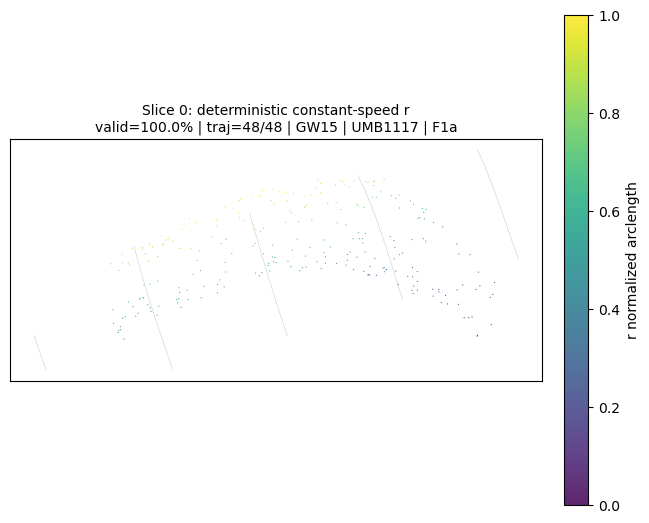

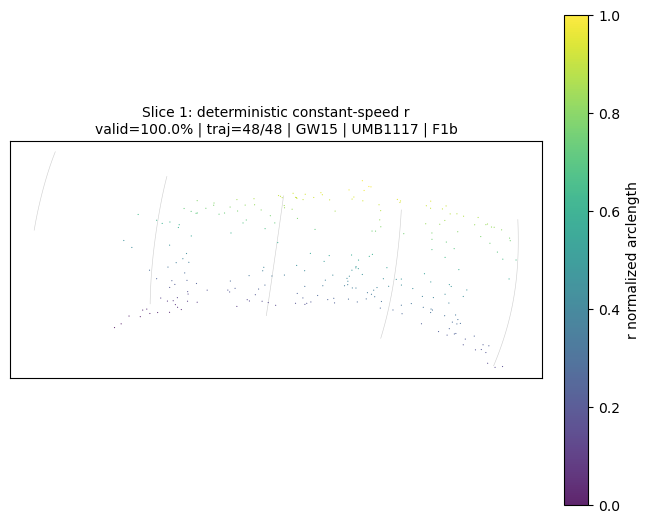

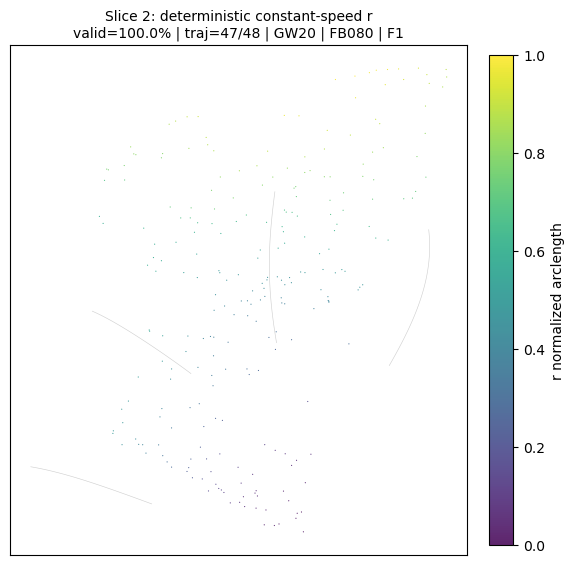

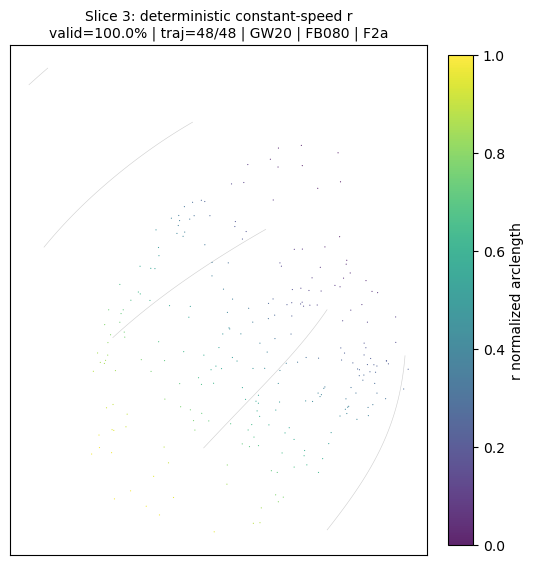

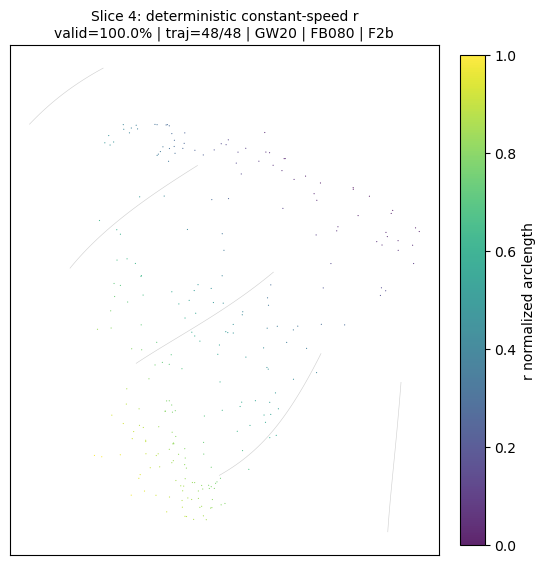

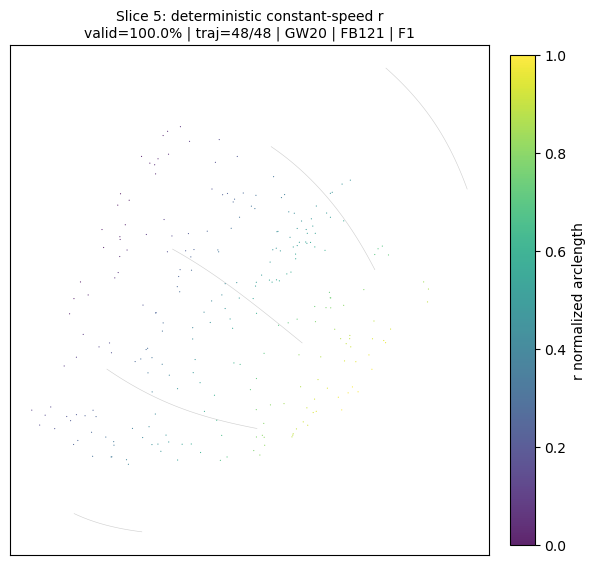

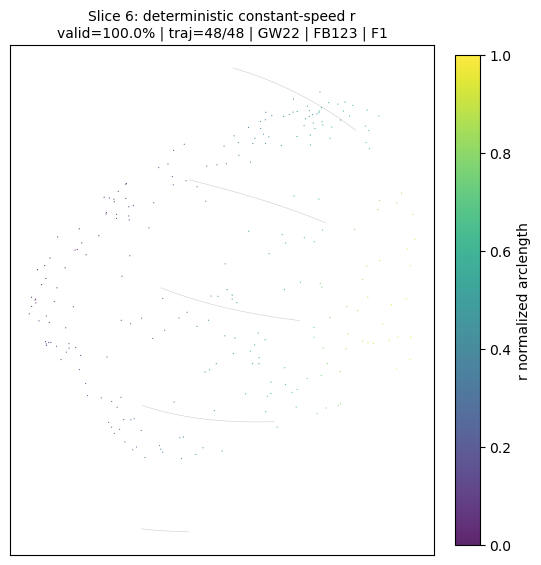

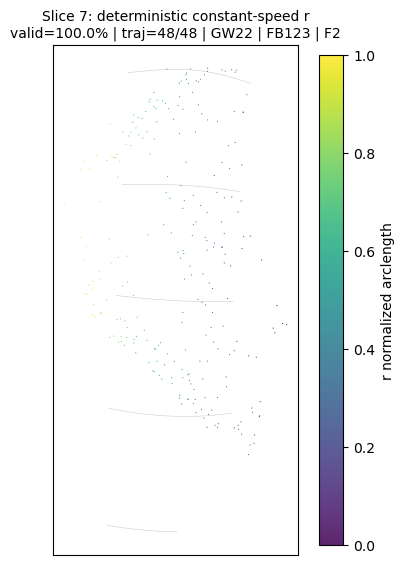

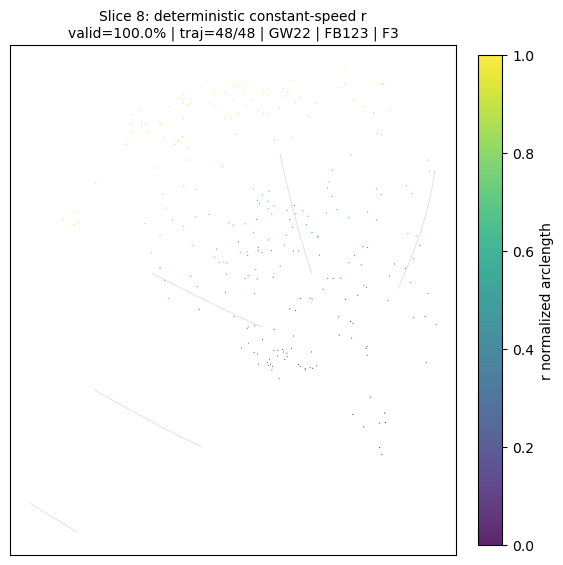

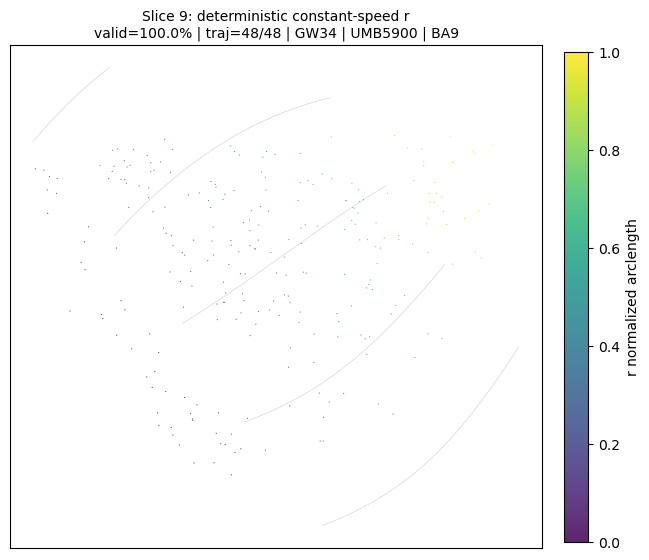

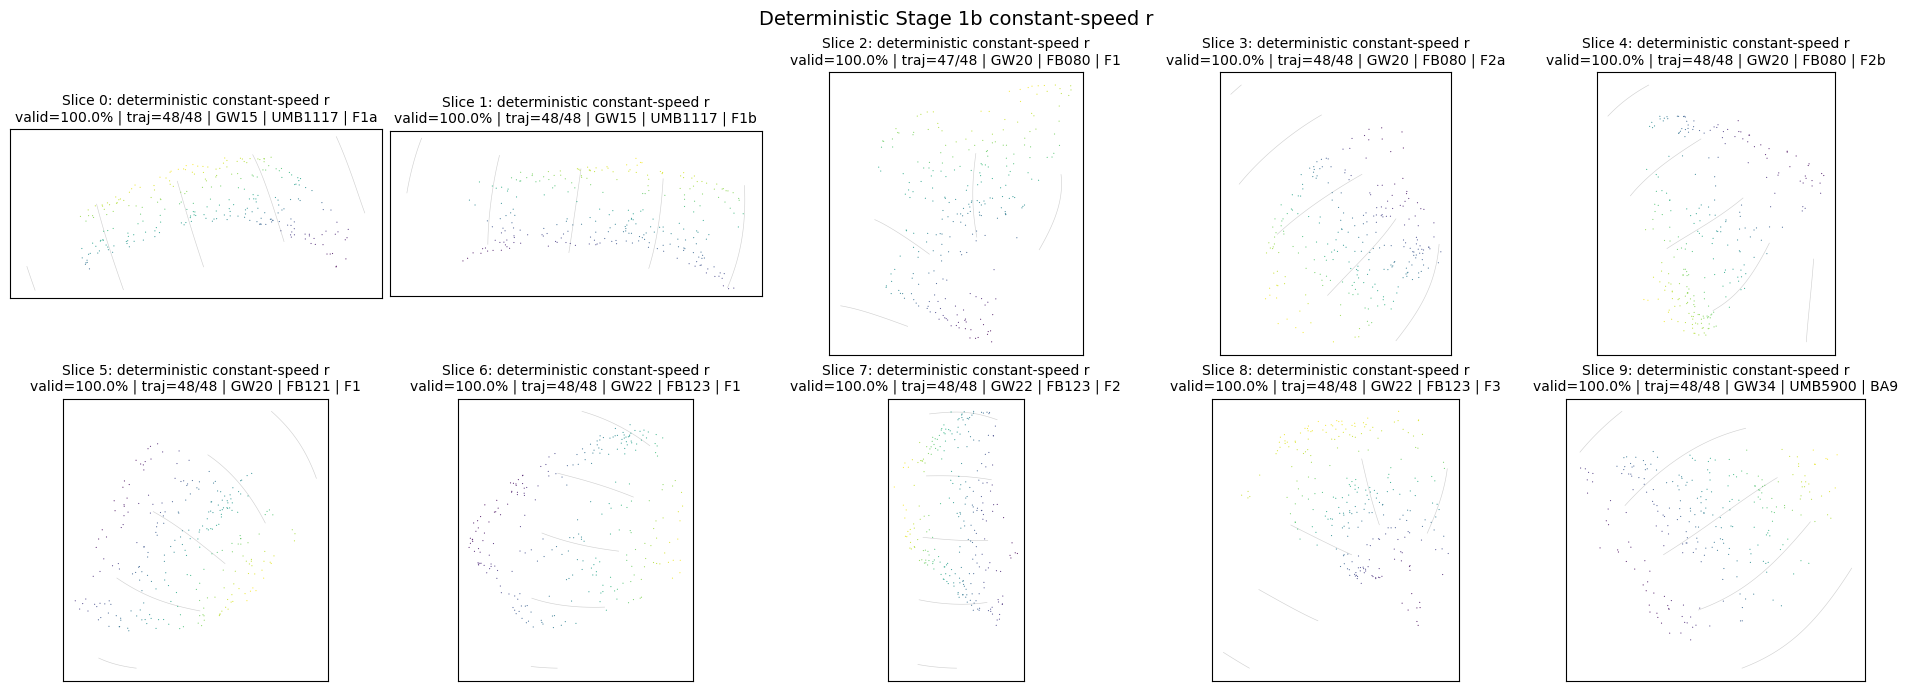

Package plots regenerated.
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_00_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_01_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_02_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_03_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_04_deterministic_r_heatmap.png
  /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/stage1b_r/plots/slice_05_determinist

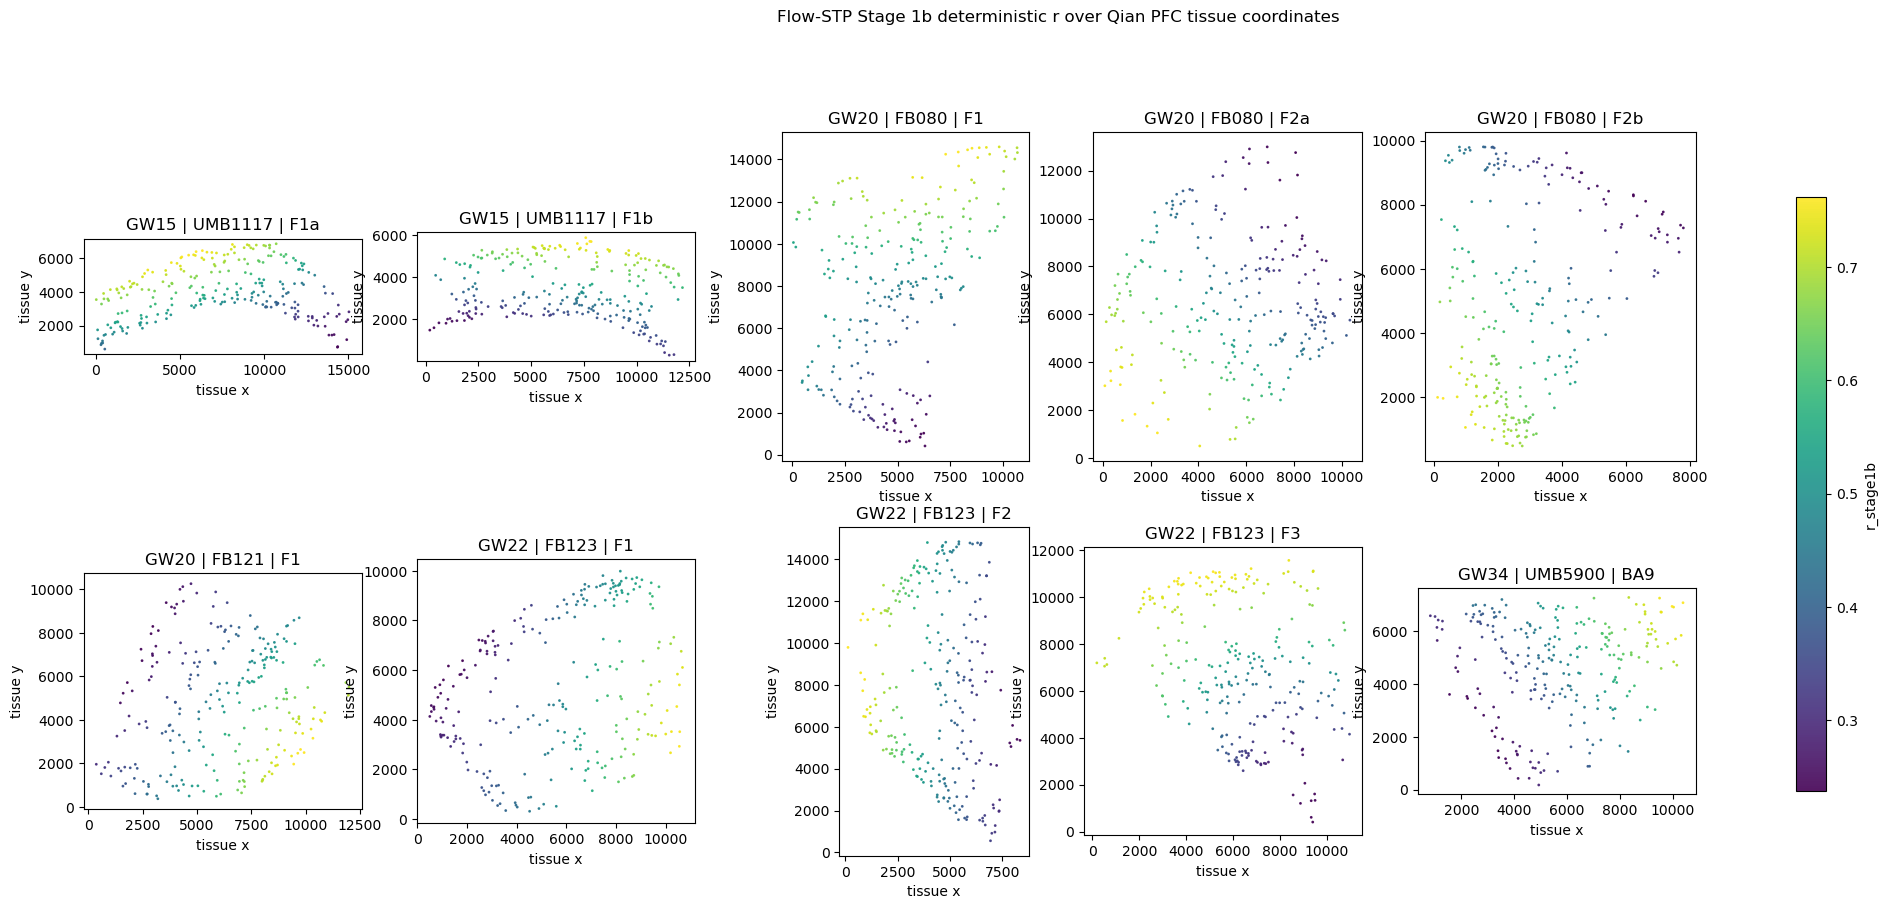


Corrected overview saved: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow/notebooks/flow_stp_package_full_stage1_workflow/smoke/manual_r_heatmaps/all_slices_stage1b_r_tissue_heatmaps_y_up.png

Focused Git status:
(no plotting change)

The Stage 1b plotting API now uses standard Cartesian orientation: tissue y increases toward the top of each plot.


In [24]:
from __future__ import annotations

from pathlib import Path
import importlib
import math
import py_compile
import re
import shutil
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================================
# LOCATE REPOSITORY
# ============================================================================

def run_command(command, *, cwd=None, check=True):
    result = subprocess.run(
        [str(item) for item in command],
        cwd=cwd,
        capture_output=True,
        text=True,
        check=False,
    )

    if check and result.returncode != 0:
        raise RuntimeError(
            f"Command failed: {' '.join(map(str, command))}\n\n"
            f"STDOUT:\n{result.stdout}\n\n"
            f"STDERR:\n{result.stderr}"
        )

    return result


REPO_ROOT = Path(
    run_command(
        ["git", "rev-parse", "--show-toplevel"]
    ).stdout.strip()
).resolve()

PLOTTING_PATH = (
    REPO_ROOT
    / "src"
    / "flow_stp"
    / "stage1"
    / "stage1b_plotting.py"
)

if not PLOTTING_PATH.is_file():
    raise FileNotFoundError(
        f"Stage 1b plotting module not found: {PLOTTING_PATH}"
    )

print("Repository:", REPO_ROOT)
print("Updating:", PLOTTING_PATH.relative_to(REPO_ROOT))


# ============================================================================
# REMOVE PACKAGE-LEVEL Y-AXIS INVERSION
# ============================================================================

source = PLOTTING_PATH.read_text(encoding="utf-8")
updated_lines = []
removed_calls = []

for line_number, line in enumerate(source.splitlines(), start=1):
    stripped = line.strip()

    # Match standalone calls such as:
    # axis.invert_yaxis()
    # ax.invert_yaxis()
    # axes[row, col].invert_yaxis()
    if (
        ".invert_yaxis()" in stripped
        and not stripped.startswith("#")
    ):
        indentation = line[: len(line) - len(line.lstrip())]

        removed_calls.append(
            (line_number, stripped)
        )

        updated_lines.append(
            indentation
            + "# Cartesian tissue orientation: y increases upward."
        )
    else:
        updated_lines.append(line)

updated_source = "\n".join(updated_lines).rstrip() + "\n"

if removed_calls:
    backup_stamp = time.strftime("%Y%m%d_%H%M%S")
    backup_path = PLOTTING_PATH.with_name(
        f"{PLOTTING_PATH.name}.backup_{backup_stamp}"
    )

    shutil.copy2(PLOTTING_PATH, backup_path)

    PLOTTING_PATH.write_text(
        updated_source,
        encoding="utf-8",
    )

    print("\nRemoved y-axis inversion calls:")

    for line_number, original_line in removed_calls:
        print(f"  line {line_number}: {original_line}")

    print(
        "\nBackup:",
        backup_path.relative_to(REPO_ROOT),
    )

else:
    print(
        "\nNo active invert_yaxis() calls were found. "
        "The package may already use Cartesian orientation."
    )


# Check for any remaining active inversions.
remaining_active_inversions = [
    (line_number, line.strip())
    for line_number, line in enumerate(
        PLOTTING_PATH.read_text(
            encoding="utf-8"
        ).splitlines(),
        start=1,
    )
    if (
        ".invert_yaxis()" in line
        and not line.strip().startswith("#")
    )
]

if remaining_active_inversions:
    raise RuntimeError(
        "Some active invert_yaxis() calls remain:\n"
        + "\n".join(
            f"  line {line_number}: {line}"
            for line_number, line
            in remaining_active_inversions
        )
    )


# ============================================================================
# SYNTAX CHECK AND RELOAD
# ============================================================================

py_compile.compile(
    str(PLOTTING_PATH),
    doraise=True,
)

print("\nSyntax check: OK")

importlib.invalidate_caches()

for module_name in list(sys.modules):
    if (
        module_name
        == "flow_stp.stage1.stage1b_plotting"
    ):
        del sys.modules[module_name]

from flow_stp.stage1 import (
    Stage1BPlotConfig,
    plot_stage1b_r,
)

print("Plotting module reload: OK")


# ============================================================================
# REGENERATE PACKAGE PLOTS WHEN stage1b IS IN MEMORY
# ============================================================================

if "stage1b" in globals():
    print("\nRegenerating package Stage 1b-r plots...")

    corrected_plot_config = (
        plot_config
        if "plot_config" in globals()
        else Stage1BPlotConfig(
            display=True,
            save_png=True,
            save_pdf=False,
            dpi=300,
        )
    )

    corrected_r_plot_artifacts = plot_stage1b_r(
        stage1b.r,
        config=corrected_plot_config,
    )

    print("Package plots regenerated.")

    for path in corrected_r_plot_artifacts.files:
        print(" ", path)

else:
    print(
        "\nstage1b is not currently in memory, so package plots "
        "were not regenerated."
    )


# ============================================================================
# REGENERATE THE NOTEBOOK OVERVIEW WITH Y INCREASING UPWARD
# ============================================================================

if "stage1b" in globals():
    r_cells = stage1b.r.cells.copy()

    def first_existing(
        frame,
        candidates,
        *,
        required=True,
    ):
        for candidate in candidates:
            if candidate in frame.columns:
                return candidate

        if required:
            raise KeyError(
                "None of these columns were found: "
                + ", ".join(candidates)
            )

        return None


    x_column = first_existing(
        r_cells,
        ("x", "spatial_x", "raw_x"),
    )

    y_column = first_existing(
        r_cells,
        ("y", "spatial_y", "raw_y"),
    )

    r_column = first_existing(
        r_cells,
        (
            "r_stage1b",
            "r_normalized",
            "r_deterministic",
            "r",
        ),
    )

    valid_column = first_existing(
        r_cells,
        (
            "r_valid",
            "assign_valid",
            "assignment_valid",
            "valid",
        ),
        required=False,
    )

    slice_ids = sorted(
        int(value)
        for value in pd.unique(r_cells["slice_id"])
    )

    ncols = min(5, max(1, len(slice_ids)))
    nrows = int(
        math.ceil(len(slice_ids) / ncols)
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5.2 * ncols, 4.7 * nrows),
        squeeze=False,
    )

    scatter_for_colorbar = None

    for axis, slice_id in zip(
        axes.ravel(),
        slice_ids,
    ):
        table = r_cells[
            r_cells["slice_id"].astype(int)
            == slice_id
        ].copy()

        valid = (
            np.isfinite(
                table[x_column].to_numpy(dtype=float)
            )
            & np.isfinite(
                table[y_column].to_numpy(dtype=float)
            )
            & np.isfinite(
                table[r_column].to_numpy(dtype=float)
            )
        )

        if valid_column is not None:
            valid &= (
                table[valid_column]
                .astype(bool)
                .to_numpy()
            )

        table = table.loc[valid]

        scatter_for_colorbar = axis.scatter(
            table[x_column],
            table[y_column],
            c=table[r_column],
            s=1.0,
            alpha=0.9,
            cmap="viridis",
            rasterized=True,
        )

        if "panel_df_flow_stp" in globals():
            panel_hit = panel_df_flow_stp[
                panel_df_flow_stp[
                    "slice_id"
                ].astype(int)
                == slice_id
            ]
        else:
            panel_hit = pd.DataFrame()

        if (
            len(panel_hit)
            and "panel_key" in panel_hit.columns
        ):
            title = str(
                panel_hit.iloc[0]["panel_key"]
            )
        else:
            title = f"slice {slice_id}"

        axis.set_title(title)
        axis.set_aspect("equal")

        # Deliberately do not call invert_yaxis().
        # Standard Cartesian orientation means y increases upward.
        axis.set_xlabel("tissue x")
        axis.set_ylabel("tissue y")

    for axis in axes.ravel()[len(slice_ids):]:
        axis.axis("off")

    if scatter_for_colorbar is not None:
        colorbar = fig.colorbar(
            scatter_for_colorbar,
            ax=list(
                axes.ravel()[: len(slice_ids)]
            ),
            shrink=0.82,
        )
        colorbar.set_label(r_column)

    fig.suptitle(
        "Flow-STP Stage 1b deterministic r over "
        "Qian PFC tissue coordinates",
        y=1.01,
    )

    if "MANUAL_PLOT_OUTPUT" in globals():
        corrected_output_dir = Path(
            MANUAL_PLOT_OUTPUT
        )
    else:
        corrected_output_dir = (
            REPO_ROOT
            / "notebooks"
            / "flow_stp_package_full_stage1_workflow"
            / "corrected_r_heatmaps"
        )

    corrected_output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    corrected_overview_path = (
        corrected_output_dir
        / "all_slices_stage1b_r_tissue_heatmaps_y_up.png"
    )

    fig.savefig(
        corrected_overview_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(
        "\nCorrected overview saved:",
        corrected_overview_path,
    )


# ============================================================================
# FINAL STATUS
# ============================================================================

print("\nFocused Git status:")

print(
    run_command(
        [
            "git",
            "status",
            "--short",
            "--",
            "src/flow_stp/stage1/stage1b_plotting.py",
        ],
        cwd=REPO_ROOT,
    ).stdout.strip()
    or "(no plotting change)"
)

print(
    "\nThe Stage 1b plotting API now uses standard Cartesian "
    "orientation: tissue y increases toward the top of each plot."
)

In [29]:
from __future__ import annotations

from pathlib import Path
import importlib
import py_compile
import subprocess
import sys


# ============================================================================
# SETTINGS
# ============================================================================

STAGE1_FIX_COMMIT_MESSAGE = (
    "Fix Stage 1b runtime and tissue plot orientation"
)

LOADER_COMMIT_MESSAGE = (
    "Add Qian PFC Stage 1 data loader"
)


# ============================================================================
# HELPERS
# ============================================================================

def run_command(
    command,
    *,
    cwd=None,
    check=True,
    timeout=None,
):
    result = subprocess.run(
        [str(item) for item in command],
        cwd=cwd,
        capture_output=True,
        text=True,
        check=False,
        timeout=timeout,
    )

    if check and result.returncode != 0:
        raise RuntimeError(
            f"Command failed:\n"
            f"  {' '.join(map(str, command))}\n\n"
            f"STDOUT:\n{result.stdout}\n\n"
            f"STDERR:\n{result.stderr}"
        )

    return result


def section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


repo_root = Path(
    run_command(
        ["git", "rev-parse", "--show-toplevel"]
    ).stdout.strip()
).resolve()


def git(*args, check=True, timeout=None):
    return run_command(
        ["git", *args],
        cwd=repo_root,
        check=check,
        timeout=timeout,
    )


def staged_paths():
    return [
        line.strip()
        for line in git(
            "diff",
            "--cached",
            "--name-only",
        ).stdout.splitlines()
        if line.strip()
    ]


def commit_staged_changes(message):
    whitespace_result = git(
        "diff",
        "--cached",
        "--check",
        check=False,
    )

    if whitespace_result.returncode != 0:
        raise RuntimeError(
            "Git found whitespace errors. Commit aborted.\n\n"
            + whitespace_result.stdout
            + whitespace_result.stderr
        )

    has_staged_changes = (
        git(
            "diff",
            "--cached",
            "--quiet",
            check=False,
        ).returncode
        != 0
    )

    if not has_staged_changes:
        raise RuntimeError(
            "No changes are staged for this commit."
        )

    commit_result = git(
        "commit",
        "-m",
        message,
        check=False,
    )

    if commit_result.returncode != 0:
        raise RuntimeError(
            f"Git could not create commit {message!r}.\n\n"
            + commit_result.stdout
            + commit_result.stderr
        )

    print(commit_result.stdout.strip())


# ============================================================================
# REPOSITORY PRECHECK
# ============================================================================

section("REPOSITORY")

branch = git(
    "branch",
    "--show-current",
).stdout.strip()

head = git(
    "log",
    "-1",
    "--oneline",
).stdout.strip()

print("Repository:", repo_root)
print("Python:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Branch:", branch)
print("HEAD:", head)


if branch != "experiment/two-stage-anatomical-axis":
    raise RuntimeError(
        "This cell expected branch "
        "'experiment/two-stage-anatomical-axis', but the active "
        f"branch is {branch!r}."
    )


# Refuse to mix this operation with files staged manually beforehand.
previously_staged = staged_paths()

if previously_staged:
    raise RuntimeError(
        "Files are already staged. Unstage them before running "
        "this cleanup cell:\n"
        + "\n".join(
            f"  - {path}"
            for path in previously_staged
        )
    )

print("No previously staged files: OK")


# ============================================================================
# REMOVE TEMPORARY INSTALLER BACKUPS
# ============================================================================

section("TEMPORARY BACKUPS")

package_root = repo_root / "src" / "flow_stp"

if not package_root.is_dir():
    raise FileNotFoundError(
        f"Package directory not found: {package_root}"
    )

backup_paths = sorted(
    package_root.rglob("*.backup_*")
)

if backup_paths:
    for backup_path in backup_paths:
        backup_path.unlink()

        print(
            "Removed:",
            backup_path.relative_to(repo_root),
        )
else:
    print("No temporary package backups remain.")


# ============================================================================
# ENSURE PACKAGED data DIRECTORY IS NOT IGNORED
# ============================================================================

section("GITIGNORE AND LOADER VISIBILITY")

gitignore_path = repo_root / ".gitignore"

gitignore_text = (
    gitignore_path.read_text(encoding="utf-8")
    if gitignore_path.exists()
    else ""
)

required_gitignore_exceptions = [
    "!src/flow_stp/data/",
    "!src/flow_stp/data/*.py",
]

existing_gitignore_lines = {
    line.strip()
    for line in gitignore_text.splitlines()
}

missing_gitignore_exceptions = [
    line
    for line in required_gitignore_exceptions
    if line not in existing_gitignore_lines
]

if missing_gitignore_exceptions:
    with gitignore_path.open(
        "a",
        encoding="utf-8",
    ) as handle:

        if (
            gitignore_text
            and not gitignore_text.endswith("\n")
        ):
            handle.write("\n")

        handle.write(
            "\n"
            "# Keep packaged dataset loaders under version control\n"
        )

        for line in missing_gitignore_exceptions:
            handle.write(line + "\n")

    print("Added .gitignore exceptions:")

    for line in missing_gitignore_exceptions:
        print(" ", line)

else:
    print(
        "Required src/flow_stp/data exceptions are already "
        "present in .gitignore."
    )


loader_files = [
    repo_root
    / "src"
    / "flow_stp"
    / "data"
    / "__init__.py",

    repo_root
    / "src"
    / "flow_stp"
    / "data"
    / "qian_pfc.py",
]


for path in loader_files:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required loader file is missing: {path}"
        )

    relative_path = str(
        path.relative_to(repo_root)
    )

    tracked_result = git(
        "ls-files",
        "--error-unmatch",
        "--",
        relative_path,
        check=False,
    )

    if tracked_result.returncode == 0:
        print(
            "Tracked by Git:",
            relative_path,
        )
        continue

    visible_untracked = {
        line.strip()
        for line in git(
            "ls-files",
            "--others",
            "--exclude-standard",
            "--",
            relative_path,
        ).stdout.splitlines()
        if line.strip()
    }

    if relative_path not in visible_untracked:
        ignore_details = git(
            "check-ignore",
            "-v",
            "--",
            relative_path,
            check=False,
        ).stdout.strip()

        raise RuntimeError(
            "The loader file is not visible to Git:\n"
            f"  {relative_path}\n\n"
            "Ignore details:\n"
            f"{ignore_details or '(none)'}"
        )

    print(
        "Visible untracked file:",
        relative_path,
    )


print("Loader package is visible to Git: OK")


print("\nCurrent loader-related status:")

loader_visibility_status = git(
    "status",
    "--short",
    "--untracked-files=all",
    "--",
    ".gitignore",
    "src/flow_stp/data",
).stdout.strip()

print(
    loader_visibility_status
    or "(no loader-related changes)"
)


# ============================================================================
# REQUIRED FILES
# ============================================================================

section("REQUIRED FILES")

required_files = [
    repo_root
    / "src"
    / "flow_stp"
    / "__init__.py",

    repo_root
    / "src"
    / "flow_stp"
    / "stage1"
    / "stage1b.py",

    repo_root
    / "src"
    / "flow_stp"
    / "stage1"
    / "stage1b_plotting.py",

    *loader_files,

    repo_root
    / "tests"
    / "test_qian_pfc_loader.py",
]

missing_files = [
    path
    for path in required_files
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Required files are missing:\n"
        + "\n".join(
            f"  - {path.relative_to(repo_root)}"
            for path in missing_files
        )
    )

for path in required_files:
    print(
        "FOUND:",
        path.relative_to(repo_root),
    )


# ============================================================================
# VERIFY THE TWO STAGE 1B FIXES
# ============================================================================

section("STAGE 1B FIX VALIDATION")

stage1b_path = (
    repo_root
    / "src"
    / "flow_stp"
    / "stage1"
    / "stage1b.py"
)

stage1b_plotting_path = (
    repo_root
    / "src"
    / "flow_stp"
    / "stage1"
    / "stage1b_plotting.py"
)

stage1b_source = stage1b_path.read_text(
    encoding="utf-8"
)

plotting_source = stage1b_plotting_path.read_text(
    encoding="utf-8"
)


required_runtime_markers = [
    "def _exec_runtime_source(",
    "types.ModuleType",
    "sys.modules[module_name]",
    'filename="_stage1b_ell_source.py"',
    'filename="_stage1b_r_source.py"',
]

missing_runtime_markers = [
    marker
    for marker in required_runtime_markers
    if marker not in stage1b_source
]

if missing_runtime_markers:
    raise RuntimeError(
        "The Python 3.11 Stage 1b runtime fix is incomplete. "
        "Missing markers:\n"
        + "\n".join(
            f"  - {marker}"
            for marker in missing_runtime_markers
        )
    )

print(
    "Registered runtime-module execution fix: OK"
)


active_y_inversions = [
    (line_number, line.strip())
    for line_number, line in enumerate(
        plotting_source.splitlines(),
        start=1,
    )
    if (
        ".invert_yaxis()" in line
        and not line.strip().startswith("#")
    )
]

if active_y_inversions:
    raise RuntimeError(
        "Active y-axis inversion calls remain in "
        "stage1b_plotting.py:\n"
        + "\n".join(
            f"  line {line_number}: {line}"
            for line_number, line
            in active_y_inversions
        )
    )

print(
    "Tissue plots use Cartesian y-up orientation: OK"
)


# ============================================================================
# PYTHON SYNTAX
# ============================================================================

section("PYTHON SYNTAX")

for path in required_files:
    py_compile.compile(
        str(path),
        doraise=True,
    )

    print(
        "OK:",
        path.relative_to(repo_root),
    )


# ============================================================================
# INSTALL IN THE CURRENT NOTEBOOK ENVIRONMENT
# ============================================================================

section("EDITABLE INSTALL")

install_result = run_command(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-e",
        str(repo_root),
    ],
    cwd=repo_root,
    check=False,
    timeout=900,
)

print(install_result.stdout)

if install_result.returncode != 0:
    if install_result.stderr:
        print(install_result.stderr)

    raise RuntimeError(
        "Editable installation failed in the active "
        "notebook environment."
    )

print("Editable installation: PASS")


# ============================================================================
# IMPORT VALIDATION
# ============================================================================

section("PACKAGE IMPORTS")

importlib.invalidate_caches()

for module_name in list(sys.modules):
    if (
        module_name == "flow_stp"
        or module_name.startswith("flow_stp.")
    ):
        del sys.modules[module_name]


import flow_stp

from flow_stp import (
    QianPFCConfig,
    QianPFCData,
    load_qian_pfc,
    load_qian_pfc_for_stage1,
    validate_qian_pfc_data,
)

from flow_stp.stage1 import (
    Stage1BEllConfig,
    Stage1BRConfig,
    Stage1BPlotConfig,
    plot_stage1b_r,
    run_stage1b,
)


loaded_package_path = Path(
    flow_stp.__file__
).resolve()

if package_root.resolve() not in loaded_package_path.parents:
    raise RuntimeError(
        "flow_stp imported from the wrong location:\n"
        f"  {loaded_package_path}\n\n"
        "Expected it beneath:\n"
        f"  {package_root.resolve()}"
    )


print(
    "flow_stp loaded from:",
    loaded_package_path,
)

for obj in (
    QianPFCConfig,
    QianPFCData,
    load_qian_pfc,
    load_qian_pfc_for_stage1,
    validate_qian_pfc_data,
    Stage1BEllConfig,
    Stage1BRConfig,
    Stage1BPlotConfig,
    run_stage1b,
    plot_stage1b_r,
):
    print(
        "OK:",
        getattr(
            obj,
            "__name__",
            type(obj).__name__,
        ),
    )


# ============================================================================
# RUN COMPLETE TEST SUITE
# ============================================================================

section("PYTEST")

pytest_result = run_command(
    [
        sys.executable,
        "-m",
        "pytest",
        "-q",
        str(repo_root / "tests"),
    ],
    cwd=repo_root,
    check=False,
    timeout=1200,
)

print(pytest_result.stdout)

if pytest_result.returncode != 0:
    if pytest_result.stderr:
        print(pytest_result.stderr)

    raise RuntimeError(
        "The test suite failed. No Git commits were created."
    )

print("Test suite: PASS")


# ============================================================================
# COMMIT 1 — STAGE 1B RUNTIME AND PLOT ORIENTATION
# ============================================================================

section("COMMIT 1: STAGE 1B FIXES")

stage1_fix_paths = [
    "src/flow_stp/stage1/stage1b.py",
    "src/flow_stp/stage1/stage1b_plotting.py",
]


changed_stage1_paths = {
    line.strip()
    for line in git(
        "diff",
        "--name-only",
        "--",
        *stage1_fix_paths,
    ).stdout.splitlines()
    if line.strip()
}

missing_stage1_changes = (
    set(stage1_fix_paths)
    - changed_stage1_paths
)

if missing_stage1_changes:
    raise RuntimeError(
        "Expected both Stage 1b files to contain uncommitted "
        "validated fixes, but these files show no change:\n"
        + "\n".join(
            f"  - {path}"
            for path in sorted(
                missing_stage1_changes
            )
        )
    )


git(
    "add",
    "--",
    *stage1_fix_paths,
)

commit1_staged = staged_paths()

if set(commit1_staged) != set(stage1_fix_paths):
    raise RuntimeError(
        "Unexpected files were staged for the Stage 1b commit.\n\n"
        "Expected:\n"
        + "\n".join(
            f"  - {path}"
            for path in stage1_fix_paths
        )
        + "\n\nActually staged:\n"
        + (
            "\n".join(
                f"  - {path}"
                for path in commit1_staged
            )
            or "  (none)"
        )
    )


print("Files staged:")

for path in commit1_staged:
    print(" ", path)


print("\nStaged diff summary:")

print(
    git(
        "diff",
        "--cached",
        "--stat",
    ).stdout
)


commit_staged_changes(
    STAGE1_FIX_COMMIT_MESSAGE
)


# ============================================================================
# COMMIT 2 — QIAN PFC DATA LOADER
# ============================================================================

section("COMMIT 2: QIAN PFC DATA LOADER")

loader_commit_paths = [
    ".gitignore",
    "src/flow_stp/__init__.py",
    "src/flow_stp/data/__init__.py",
    "src/flow_stp/data/qian_pfc.py",
    "tests/test_qian_pfc_loader.py",
]


git(
    "add",
    "--",
    *loader_commit_paths,
)

commit2_staged = staged_paths()

unexpected_commit2_paths = (
    set(commit2_staged)
    - set(loader_commit_paths)
)

if unexpected_commit2_paths:
    raise RuntimeError(
        "Unexpected files were staged for the loader commit:\n"
        + "\n".join(
            f"  - {path}"
            for path in sorted(
                unexpected_commit2_paths
            )
        )
    )


required_loader_staged_paths = {
    "src/flow_stp/__init__.py",
    "src/flow_stp/data/__init__.py",
    "src/flow_stp/data/qian_pfc.py",
    "tests/test_qian_pfc_loader.py",
}

missing_loader_staged_paths = (
    required_loader_staged_paths
    - set(commit2_staged)
)

if missing_loader_staged_paths:
    raise RuntimeError(
        "Required loader files were not staged:\n"
        + "\n".join(
            f"  - {path}"
            for path in sorted(
                missing_loader_staged_paths
            )
        )
    )


print("Files staged:")

for path in commit2_staged:
    print(" ", path)


print("\nStaged diff summary:")

print(
    git(
        "diff",
        "--cached",
        "--stat",
    ).stdout
)


commit_staged_changes(
    LOADER_COMMIT_MESSAGE
)


# ============================================================================
# FINAL REPORT
# ============================================================================

section("FINAL REPORT")

print("Recent commits:")

print(
    git(
        "log",
        "-4",
        "--oneline",
        "--decorate",
    ).stdout
)


print("Package-related status:")

focused_status = git(
    "status",
    "--short",
    "--untracked-files=all",
    "--",
    ".gitignore",
    "pyproject.toml",
    "src/flow_stp",
    "tests",
).stdout.strip()

print(
    focused_status
    or "(package and tests clean)"
)


print("\nRemaining repository changes:")

remaining_status = git(
    "status",
    "--short",
).stdout.strip()

print(
    remaining_status
    or "(working tree clean)"
)


print(
    "\nCleanup and commits completed successfully.\n"
    "Research notebooks and generated workflow outputs were not "
    "staged by this cell."
)


REPOSITORY
Repository: /weka/scratch/uchitra1/users/joquinn4/projects/STP flow
Python: /weka/scratch/uchitra1/users/joquinn4/envs/tsc/bin/python3.11
Python version: 3.11.14
Branch: experiment/two-stage-anatomical-axis
HEAD: fe05a10 Add callable Stage 1b pipeline and plotting API
No previously staged files: OK

TEMPORARY BACKUPS
No temporary package backups remain.

GITIGNORE AND LOADER VISIBILITY
Required src/flow_stp/data exceptions are already present in .gitignore.
Visible untracked file: src/flow_stp/data/__init__.py
Visible untracked file: src/flow_stp/data/qian_pfc.py
Loader package is visible to Git: OK

Current loader-related status:
M .gitignore
?? src/flow_stp/data/__init__.py
?? src/flow_stp/data/qian_pfc.py

REQUIRED FILES
FOUND: src/flow_stp/__init__.py
FOUND: src/flow_stp/stage1/stage1b.py
FOUND: src/flow_stp/stage1/stage1b_plotting.py
FOUND: src/flow_stp/data/__init__.py
FOUND: src/flow_stp/data/qian_pfc.py
FOUND: tests/test_qian_pfc_loader.py

STAGE 1B FIX VALIDATION
R

RuntimeError: Expected both Stage 1b files to contain uncommitted validated fixes, but these files show no change:
  - src/flow_stp/stage1/stage1b_plotting.py

In [28]:
import subprocess
import sys

subprocess.run(
    [sys.executable, "-m", "pip", "install", "pytest"],
    check=True,
)

  Using cached pytest-9.1.1-py3-none-any.whl.metadata (7.6 kB)
  Using cached iniconfig-2.3.0-py3-none-any.whl.metadata (2.5 kB)
  Using cached pluggy-1.6.0-py3-none-any.whl.metadata (4.8 kB)
Using cached pytest-9.1.1-py3-none-any.whl (386 kB)
Using cached pluggy-1.6.0-py3-none-any.whl (20 kB)
Using cached iniconfig-2.3.0-py3-none-any.whl (7.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pytest]2m2/3 [pytest]



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


CompletedProcess(args=['/weka/scratch/uchitra1/users/joquinn4/envs/tsc/bin/python3.11', '-m', 'pip', 'install', 'pytest'], returncode=0)